# 📊 Stock Pulse — Comprehensive Model Evaluation

Run **every cell top-to-bottom**. All numbers derive from on-disk artefacts.

| # | Topic |
|---|-------|
| 0 | Setup & Data Loading |
| 1 | Model Comparison |
| 2 | Learning Curves |
| 3 | Classification Metrics (Accuracy, Precision, Recall, F1, Specificity) |
| 4 | ROC-AUC & PR-AUC |
| 5 | Regression Metrics (MAE, MSE) & Predicted vs. Actual Analysis |
| 6 | Overfitting / Underfitting / Generalisation Gap |
| 7 | Cross-Validation |
| 8 | Computational Efficiency |
| 9 | Class Imbalance |
| 10 | Interpretability — Ridge Coefficients |
| 11 | Explainability — SHAP & Permutation Importance |
| 12 | Summary Dashboard |

---
## 0. Setup & Data Loading

In [1]:
"""0.1 Imports"""
import warnings, time, itertools, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve, confusion_matrix,
    mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, precision_score, recall_score
)
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:
    display = print

def show_styled(df, caption="", fmt="{:.4f}", cmap="RdYlGn", axis=0):
    try:
        import jinja2
        return df.style.background_gradient(cmap=cmap, axis=axis).format(fmt).set_caption(caption)
    except Exception:
        if caption:
            print(f"=== {caption} ===")
        return df.round(4)

plt.rcParams.update({
    "figure.dpi": 130, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": "DejaVu Sans",
    "axes.titlesize": 13, "axes.labelsize": 11,
})
PALETTE = ["#2196F3","#FF5722","#4CAF50","#9C27B0",
           "#FF9800","#00BCD4","#E91E63","#795548","#607D8B","#FFC107"]
print("Imports OK")

Imports OK


In [2]:
"""0.2 Paths — robustly find project root"""
ROOT = Path(".").resolve()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent
if not (ROOT / "reports").exists():
    ROOT = Path("..").resolve()
OOS  = ROOT / "reports" / "oos_predictions"
REP  = ROOT / "reports"
print(f"Project root : {ROOT}")
n_p = len(list(OOS.glob("*.parquet")))
print(f"Parquet files: {n_p}")

Project root : C:\Users\USER\Documents\Group Project\Group Project_1
Parquet files: 75


In [3]:
"""0.3 Load results_long.csv"""
RESULTS = pd.read_csv(REP / "results_long.csv")
print(f"Shape   : {RESULTS.shape}")
print(f"Models  : {sorted(RESULTS['model'].unique())}")
print(f"Horizons: {sorted(RESULTS['horizon'].unique())}")
print(f"Metrics : {RESULTS['metric'].nunique()} unique")

Shape   : (36874, 7)
Models  : ['ens_rank4', 'ens_rank4_bestlgbm', 'equal_weight_universe', 'lgbm_clf', 'lgbm_reg', 'logit', 'low_vol', 'lstm_reg', 'momentum_126', 'momentum_63', 'past_winner', 'random', 'reversal_21', 'rf_clf', 'rf_reg', 'ridge', 'tabpfn_clf', 'tabpfn_reg']
Horizons: ['long', 'mid', 'short']
Metrics : 53 unique


In [4]:
"""0.4 Helpers"""
def mean_metric(metric, horizon="mid", split_type="dev", models=None):
    sub = RESULTS[
        (RESULTS["metric"] == metric) &
        (RESULTS["horizon"] == horizon) &
        (RESULTS["split_type"] == split_type)
    ]
    if models is not None:
        sub = sub[sub["model"].isin(models)]
    return sub.groupby("model")["value"].mean().sort_values(ascending=False)

PRIMARY_MODELS = ["ens_rank4","lgbm_reg","rf_reg","ridge",
                  "lgbm_clf","rf_clf","momentum_126","lstm_reg"]
ALL_MODELS  = sorted(RESULTS["model"].unique().tolist())
HORIZONS    = ["short","mid","long"]
FEATURE_LABELS = {
    "log_ret_5":"5d Ret","log_ret_10":"10d Ret","log_ret_21":"21d Ret",
    "log_ret_63":"63d Ret","log_ret_126":"126d Ret","log_ret_252":"252d Ret",
    "vol_21d":"21d Vol","vol_63d":"63d Vol","downside_vol_63d":"Downside Vol",
    "rsi_14":"RSI-14","macd_hist_norm":"MACD Hist","bollinger_pct_b_20":"Bollinger%B",
    "amihud_illiq_63d":"Amihud","zero_trade_share_63d":"Zero-Trade%",
    "rel_ret_21d":"RelRet 21d","rel_ret_63d":"RelRet 63d",
    "cs_rank_mom_63d":"CS Mom Rank","cs_rank_vol_63d":"CS Vol63",
    "cs_rank_vol_21d":"CS Vol21","index_ret_63d":"Idx Ret","index_vol_63d":"Idx Vol",
}
print("Helpers ready")

Helpers ready


In [5]:
"""0.5 Load OOS parquet files"""
t0 = time.perf_counter()

def load_oos(stem, hz="mid", fs="core"):
    p = OOS / f"{stem}_{hz}_{fs}.parquet"
    return pd.read_parquet(p) if p.exists() else pd.DataFrame()

OOS_DICT = {}
LOAD_TARGETS = [
    ("ens_rank4","mid","core"), ("lgbm_clf","mid","core"),
    ("lgbm_reg","mid","core"), ("rf_clf","mid","core"),
    ("rf_reg","mid","core"),   ("ridge","mid","core"),
    ("momentum_126","mid","core"), ("logit","mid","core"),
    ("lstm_reg","mid","core"),
    ("ens_rank4","short","core"), ("lgbm_reg","short","core"),
    ("ridge","short","core"),
    ("ens_rank4","long","core"), ("lgbm_reg","long","core"),
    ("ridge","long","core"),
]
for stem, hz, fs in LOAD_TARGETS:
    key = f"{stem}_{hz}"
    df  = load_oos(stem, hz, fs)
    if not df.empty:
        df["Date"] = pd.to_datetime(df["Date"])
        OOS_DICT[key] = df

print(f"Loaded {len(OOS_DICT)} OOS frames in {time.perf_counter()-t0:.1f}s")
for k,v in OOS_DICT.items():
    print(f"  {k:30s} rows={v.shape[0]}")

Loaded 15 OOS frames in 0.4s
  ens_rank4_mid                  rows=55840
  lgbm_clf_mid                   rows=55840
  lgbm_reg_mid                   rows=55840
  rf_clf_mid                     rows=55840
  rf_reg_mid                     rows=55840
  ridge_mid                      rows=55840
  momentum_126_mid               rows=55840
  logit_mid                      rows=55840
  lstm_reg_mid                   rows=55840
  ens_rank4_short                rows=56991
  lgbm_reg_short                 rows=56991
  ridge_short                    rows=56991
  ens_rank4_long                 rows=41935
  lgbm_reg_long                  rows=41935
  ridge_long                     rows=41935


---
## 1. Model Comparison

In [6]:
"""1.1 Summary table – key metrics across horizons (dev folds)"""
KEY_METRICS = [
    "rank_ic_mean","rank_ic_ir","top_k_precision",
    "top_k_fwd_excess_mean","portfolio_net_excess_mean",
    "portfolio_win_rate","mae_rank","rmse_rank"
]
rows = []
for hz in HORIZONS:
    for model in ALL_MODELS:
        sub = RESULTS[
            (RESULTS["model"]==model) & (RESULTS["horizon"]==hz) &
            (RESULTS["split_type"]=="dev") & (RESULTS["metric"].isin(KEY_METRICS))
        ]
        row = {"model":model,"horizon":hz}
        row.update(sub.groupby("metric")["value"].mean().to_dict())
        rows.append(row)
COMP = pd.DataFrame(rows).set_index(["model","horizon"])
COMP = COMP[[c for c in KEY_METRICS if c in COMP.columns]]
mid_comp = COMP.xs("mid",level="horizon").sort_values("rank_ic_mean",ascending=False)
display(show_styled(mid_comp, caption="Dev-set mean (mid horizon). Green=better."))

=== Dev-set mean (mid horizon). Green=better. ===


,rank_ic_mean,rank_ic_ir,top_k_precision,top_k_fwd_excess_mean,portfolio_net_excess_mean,portfolio_win_rate,mae_rank,rmse_rank
model,,,,,,,,
momentum_126,0.0662,0.2758,0.5173,0.0308,0.0041,0.4758,0.3178,0.3943
momentum_63,0.0496,0.1792,0.5095,0.0293,-0.0122,0.3219,0.3210,0.3981
ens_rank4,0.0432,0.1800,0.5116,0.0197,-0.0079,0.4373,0.3237,0.3993
ens_rank4_bestlgbm,0.0432,0.1800,0.5116,0.0197,-0.0079,0.4373,0.3237,0.3993
tabpfn_clf,0.0250,0.1078,0.5075,0.0197,-0.0178,0.3294,0.3288,0.4026
past_winner,0.0232,0.1026,0.5040,0.0323,-0.0005,0.3570,0.3258,0.4025
lstm_reg,0.0218,0.0800,0.5071,0.0147,-0.0185,0.2943,0.3296,0.4035
ridge,0.0118,0.0409,0.4995,0.0192,-0.0116,0.3712,0.3311,0.4056
rf_reg,0.0109,0.0744,0.5003,0.0144,-0.0183,0.3712,0.3311,0.4064


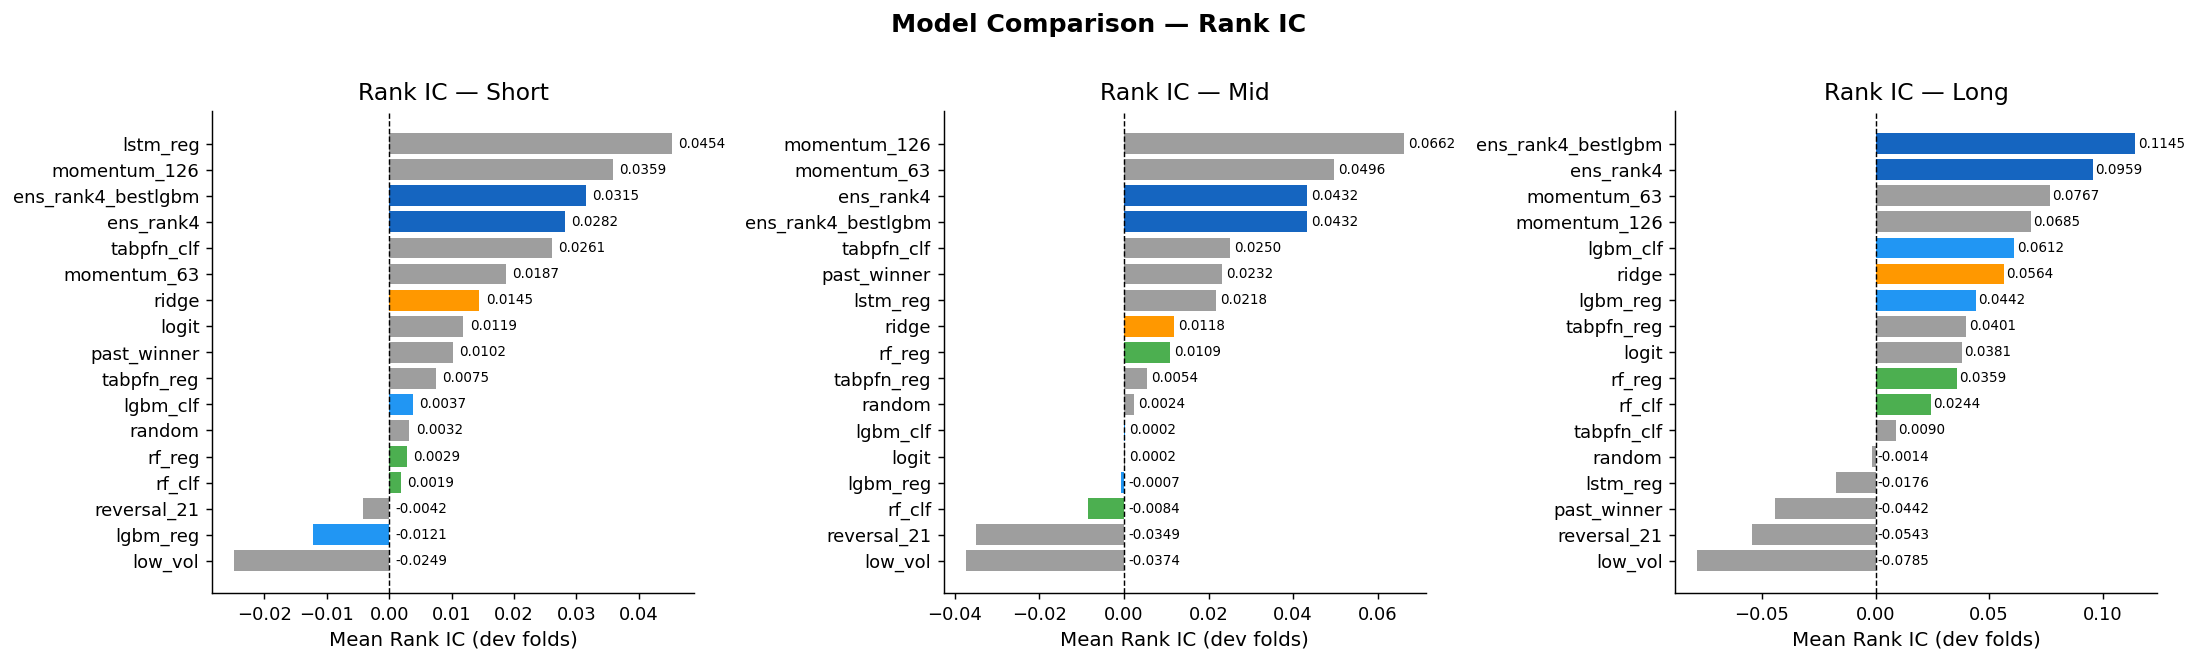

In [7]:
"""1.2 Rank IC bar chart — all three horizons"""
fig, axes = plt.subplots(1,3,figsize=(17,5))
for ax, hz in zip(axes, HORIZONS):
    ic = mean_metric("rank_ic_mean", hz, "dev").dropna()
    clrs = ["#1565C0" if "ens" in m else "#2196F3" if "lgbm" in m
            else "#4CAF50" if "rf" in m else "#FF9800" if m=="ridge"
            else "#9E9E9E" for m in ic.index]
    ax.barh(ic.index[::-1], ic.values[::-1], color=clrs[::-1])
    ax.axvline(0, color="black", lw=0.8, ls="--")
    ax.set_title(f"Rank IC — {hz.capitalize()}")
    ax.set_xlabel("Mean Rank IC (dev folds)")
    for p, v in zip(ax.patches, ic.values[::-1]):
        ax.text(max(v,0)+0.001, p.get_y()+p.get_height()/2,
                f"{v:.4f}", va="center", fontsize=7.5)
plt.suptitle("Model Comparison — Rank IC",fontsize=14,fontweight="bold",y=1.01)
plt.tight_layout(); plt.show()

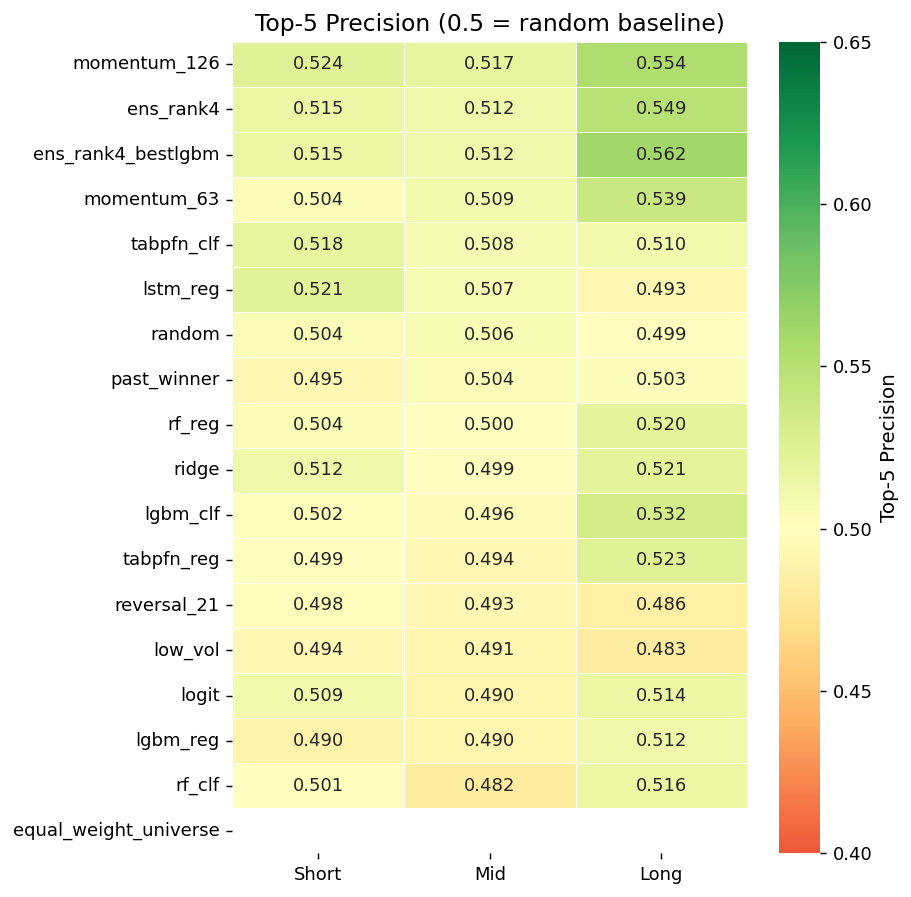

In [8]:
"""1.3 Top-5 Precision heatmap"""
prec = {}
for hz in HORIZONS:
    for m in ALL_MODELS:
        v = RESULTS[
            (RESULTS["model"]==m)&(RESULTS["horizon"]==hz)&
            (RESULTS["split_type"]=="dev")&(RESULTS["metric"]=="top_k_precision")
        ]["value"].mean()
        prec.setdefault(m,{})[hz] = v
prec_df = pd.DataFrame(prec).T.sort_values("mid",ascending=False)
prec_df.columns=["Short","Mid","Long"]
fig, ax = plt.subplots(figsize=(7,7))
sns.heatmap(prec_df.astype(float),annot=True,fmt=".3f",
            cmap="RdYlGn",center=0.5,vmin=0.4,vmax=0.65,ax=ax,
            linewidths=0.5,cbar_kws={"label":"Top-5 Precision"})
ax.set_title("Top-5 Precision (0.5 = random baseline)")
plt.tight_layout(); plt.show()

---
## 2. Learning Curves (Walk-Forward Fold Progression)

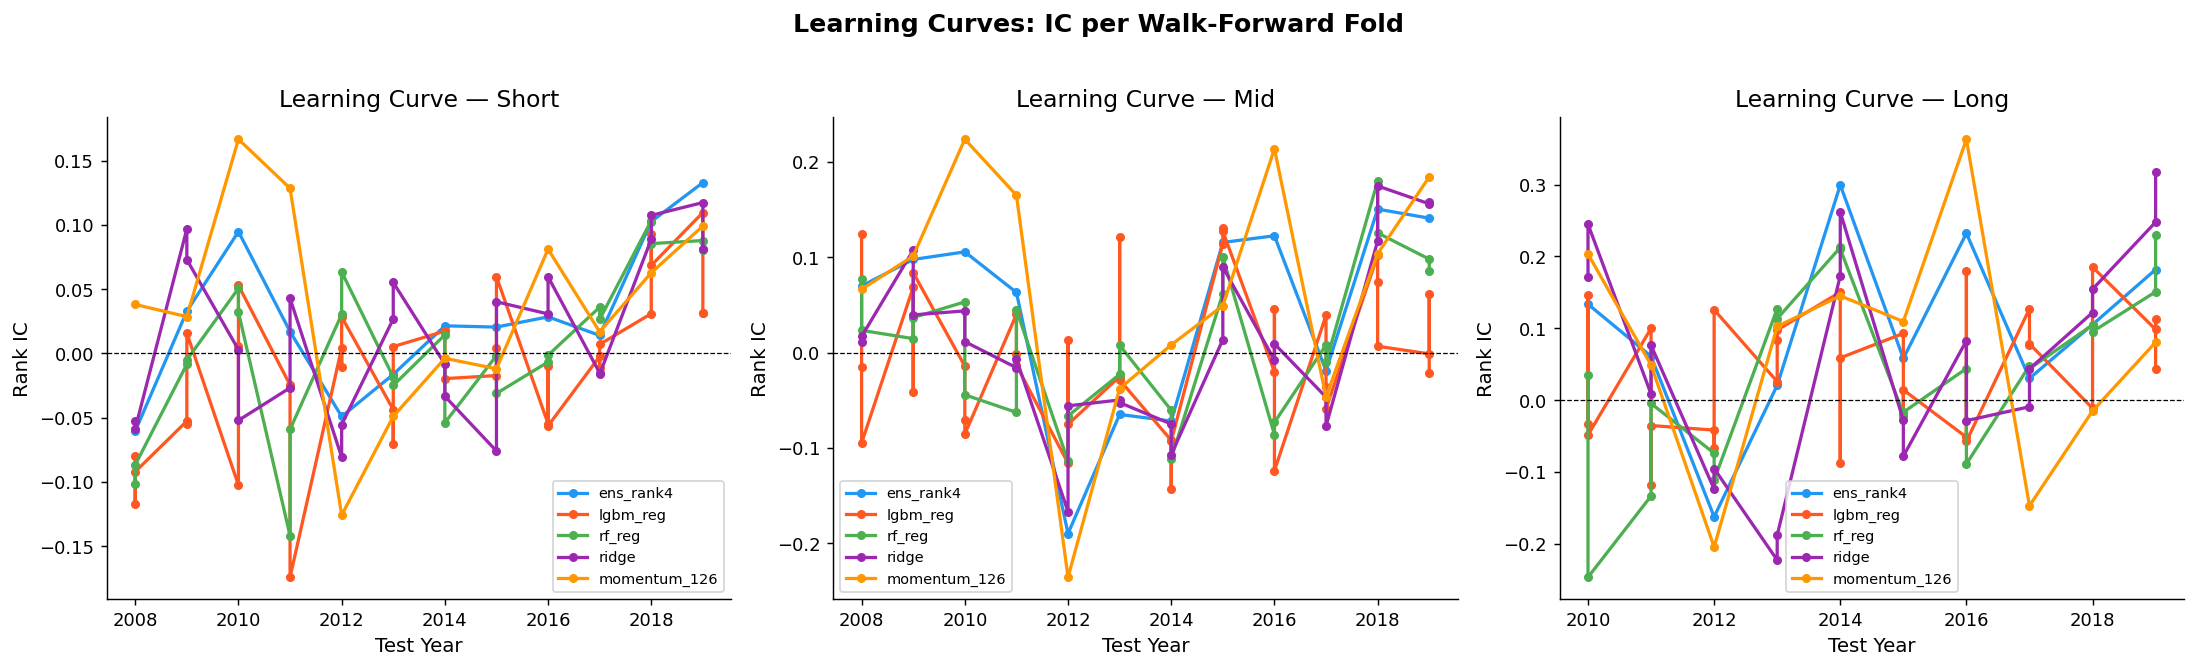

In [9]:
"""2.1 IC per fold — all horizons"""
SHOW = ["ens_rank4","lgbm_reg","rf_reg","ridge","momentum_126"]
fig, axes = plt.subplots(1,3,figsize=(17,5))
for ax, hz in zip(axes, HORIZONS):
    for i, m in enumerate(SHOW):
        sub = RESULTS[
            (RESULTS["model"]==m)&(RESULTS["horizon"]==hz)&
            (RESULTS["split_type"]=="dev")&(RESULTS["metric"]=="rank_ic_mean")
        ].copy()
        sub = sub[sub["fold"].str.startswith("dev_")].copy()
        if sub.empty: continue
        sub["year"] = sub["fold"].str.extract(r"(\d{4})")[0].astype(int)
        sub = sub.sort_values("year")
        ax.plot(sub["year"],sub["value"],marker="o",ms=4,
                label=m,color=PALETTE[i],lw=1.8)
    ax.axhline(0,color="black",lw=0.7,ls="--")
    ax.set_title(f"Learning Curve — {hz.capitalize()}")
    ax.set_xlabel("Test Year"); ax.set_ylabel("Rank IC")
    ax.legend(fontsize=8)
plt.suptitle("Learning Curves: IC per Walk-Forward Fold",
             fontsize=14,fontweight="bold",y=1.02)
plt.tight_layout(); plt.show()

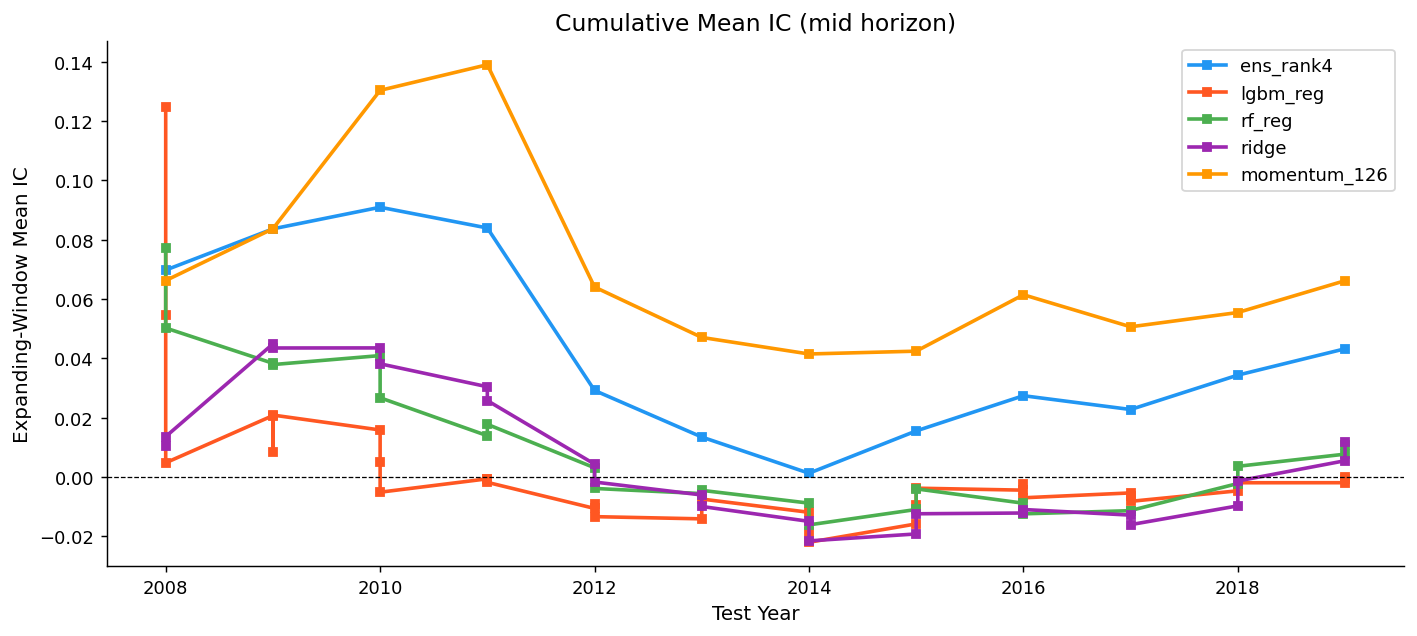

In [10]:
"""2.2 Cumulative mean IC (expanding window benefit)"""
hz = "mid"
fig, ax = plt.subplots(figsize=(11,5))
for i, m in enumerate(SHOW):
    sub = RESULTS[
        (RESULTS["model"]==m)&(RESULTS["horizon"]==hz)&
        (RESULTS["split_type"]=="dev")&(RESULTS["metric"]=="rank_ic_mean")
    ].copy()
    sub = sub[sub["fold"].str.startswith("dev_")].copy()
    if sub.empty: continue
    sub["year"] = sub["fold"].str.extract(r"(\d{4})")[0].astype(int)
    sub = sub.sort_values("year")
    sub["cum_ic"] = sub["value"].expanding().mean()
    ax.plot(sub["year"],sub["cum_ic"],marker="s",ms=4,
            label=m,color=PALETTE[i],lw=2)
ax.axhline(0,color="black",lw=0.7,ls="--")
ax.set_title(f"Cumulative Mean IC ({hz} horizon)")
ax.set_xlabel("Test Year"); ax.set_ylabel("Expanding-Window Mean IC")
ax.legend(); plt.tight_layout(); plt.show()

---
## 3. Classification Metrics — Accuracy, Precision, Recall, F1, Specificity

In [11]:
"""3.1 Compute from OOS parquets"""
clf_records = []

def _clf(df, hz, label, use_prob):
    tc = f"outperform_{hz}"
    valid = df.dropna(subset=[tc])
    if use_prob and "pred_prob" in valid.columns:
        valid = valid.dropna(subset=["pred_prob"])
        scores = valid["pred_prob"].values
    else:
        valid = valid.copy()
        valid["cs_med"] = valid.groupby("Date")["pred_score"].transform("median")
        scores = valid["pred_score"].rank(pct=True).values
    y_pred = (scores >= 0.5).astype(int)
    y_true = valid[tc].astype(int).values
    if y_true.sum() == 0 or y_true.sum() == len(y_true): return
    tn,fp,fn,tp = confusion_matrix(y_true,y_pred).ravel()
    clf_records.append({
        "Model": label, "Horizon": hz,
        "Accuracy":    accuracy_score(y_true,y_pred),
        "Precision":   precision_score(y_true,y_pred,zero_division=0),
        "Recall":      recall_score(y_true,y_pred,zero_division=0),
        "F1":          f1_score(y_true,y_pred,zero_division=0),
        "Specificity": tn/(tn+fp) if (tn+fp)>0 else float("nan"),
        "ROC-AUC":     roc_auc_score(y_true,scores),
        "PR-AUC":      average_precision_score(y_true,scores),
        "TP":int(tp),"TN":int(tn),"FP":int(fp),"FN":int(fn),
    })

for mk,hz,up in [
    ("lgbm_clf","mid",True),("rf_clf","mid",True),("logit","mid",True),
    ("ens_rank4","mid",False),("lgbm_reg","mid",False),
    ("rf_reg","mid",False),("ridge","mid",False),
]:
    if f"{mk}_{hz}" in OOS_DICT:
        _clf(OOS_DICT[f"{mk}_{hz}"],hz,mk,up)

CLF_DF = pd.DataFrame(clf_records).set_index("Model")
print("Computed for:", CLF_DF.index.tolist())
CLF_DF[["Accuracy","Precision","Recall","F1","Specificity","ROC-AUC","PR-AUC"]].round(4)

Computed for: ['lgbm_clf', 'rf_clf', 'logit', 'ens_rank4', 'lgbm_reg', 'rf_reg', 'ridge']


,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,PR-AUC
Model,,,,,,,
lgbm_clf,0.5072,0.5078,0.5259,0.5167,0.4884,0.5090,0.5093
rf_clf,0.5004,0.5015,0.4698,0.4851,0.5312,0.4989,0.4895
logit,0.5085,0.5093,0.5159,0.5126,0.5011,0.5110,0.5101
ens_rank4,0.5240,0.5250,0.5236,0.5243,0.5244,0.5294,0.5241
lgbm_reg,0.5222,0.5234,0.5177,0.5205,0.5267,0.5176,0.5105
rf_reg,0.5148,0.5157,0.5147,0.5152,0.5148,0.5155,0.5020
ridge,0.5131,0.5141,0.5131,0.5136,0.5131,0.5175,0.5142


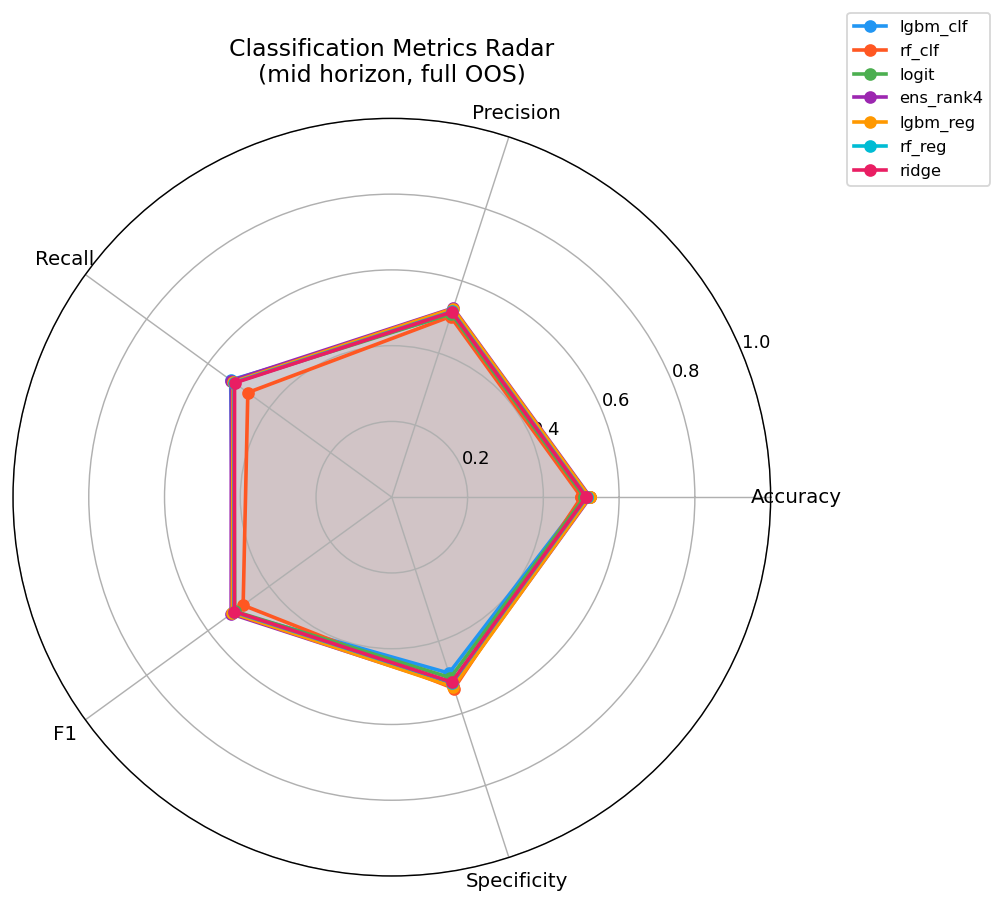

In [12]:
"""3.2 Radar chart"""
RM = ["Accuracy","Precision","Recall","F1","Specificity"]
angles = np.linspace(0,2*np.pi,len(RM),endpoint=False).tolist()+[0]
fig, ax = plt.subplots(figsize=(8,7),subplot_kw=dict(polar=True))
for i,(m,row) in enumerate(CLF_DF[RM].iterrows()):
    v = row.values.tolist()+[row.values[0]]
    ax.plot(angles,v,"o-",lw=2,label=m,color=PALETTE[i%len(PALETTE)])
    ax.fill(angles,v,alpha=0.07,color=PALETTE[i%len(PALETTE)])
ax.set_thetagrids(np.degrees(angles[:-1]),RM,fontsize=11)
ax.set_ylim(0,1)
ax.set_title("Classification Metrics Radar\n(mid horizon, full OOS)",pad=20)
ax.legend(loc="upper right",bbox_to_anchor=(1.3,1.15),fontsize=9)
plt.tight_layout(); plt.show()

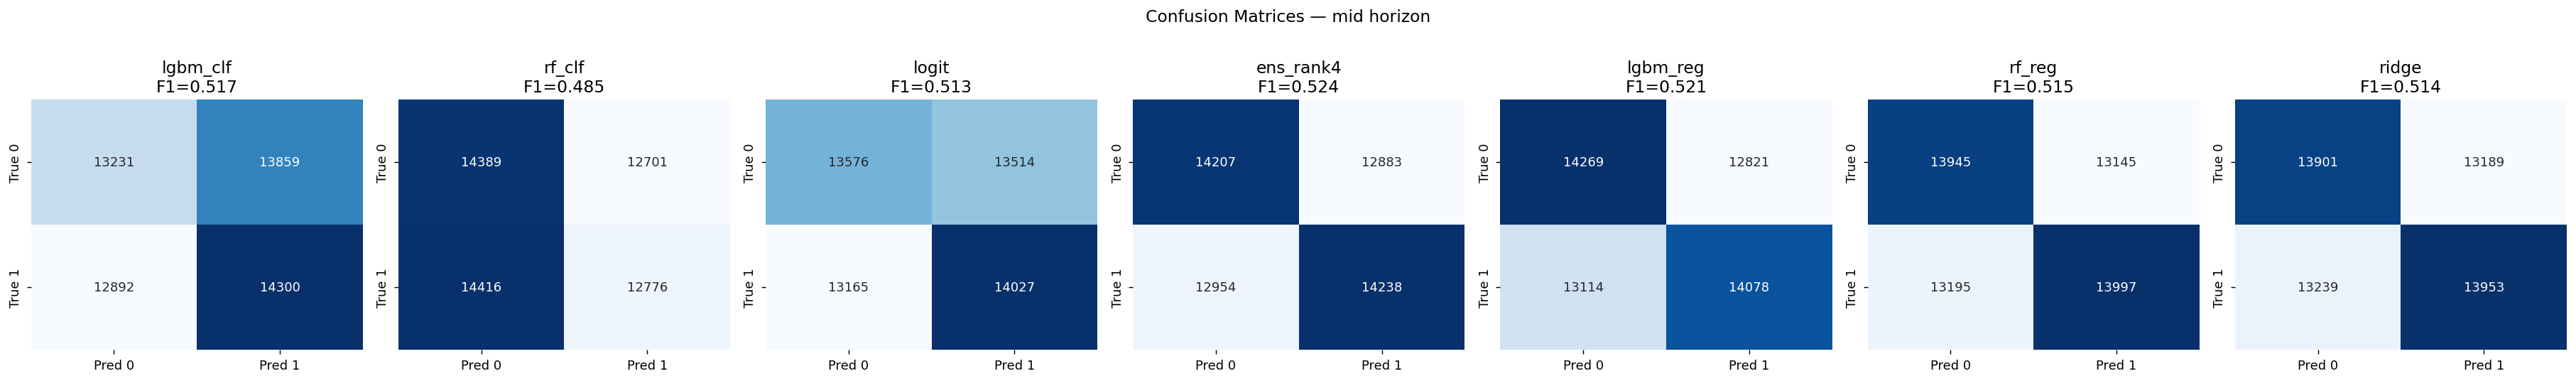

In [13]:
"""3.3 Confusion matrices"""
n = len(clf_records)
fig, axes = plt.subplots(1,n,figsize=(4*n,4))
if n == 1: axes = [axes]
for ax, rec in zip(axes, clf_records):
    cm = np.array([[rec["TN"],rec["FP"]],[rec["FN"],rec["TP"]]])
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
                xticklabels=["Pred 0","Pred 1"],
                yticklabels=["True 0","True 1"],ax=ax,cbar=False)
    ax.set_title(f'{rec["Model"]}\nF1={rec["F1"]:.3f}')
plt.suptitle("Confusion Matrices — mid horizon",fontsize=13,y=1.02)
plt.tight_layout(); plt.show()

---
## 4. ROC-AUC & PR-AUC

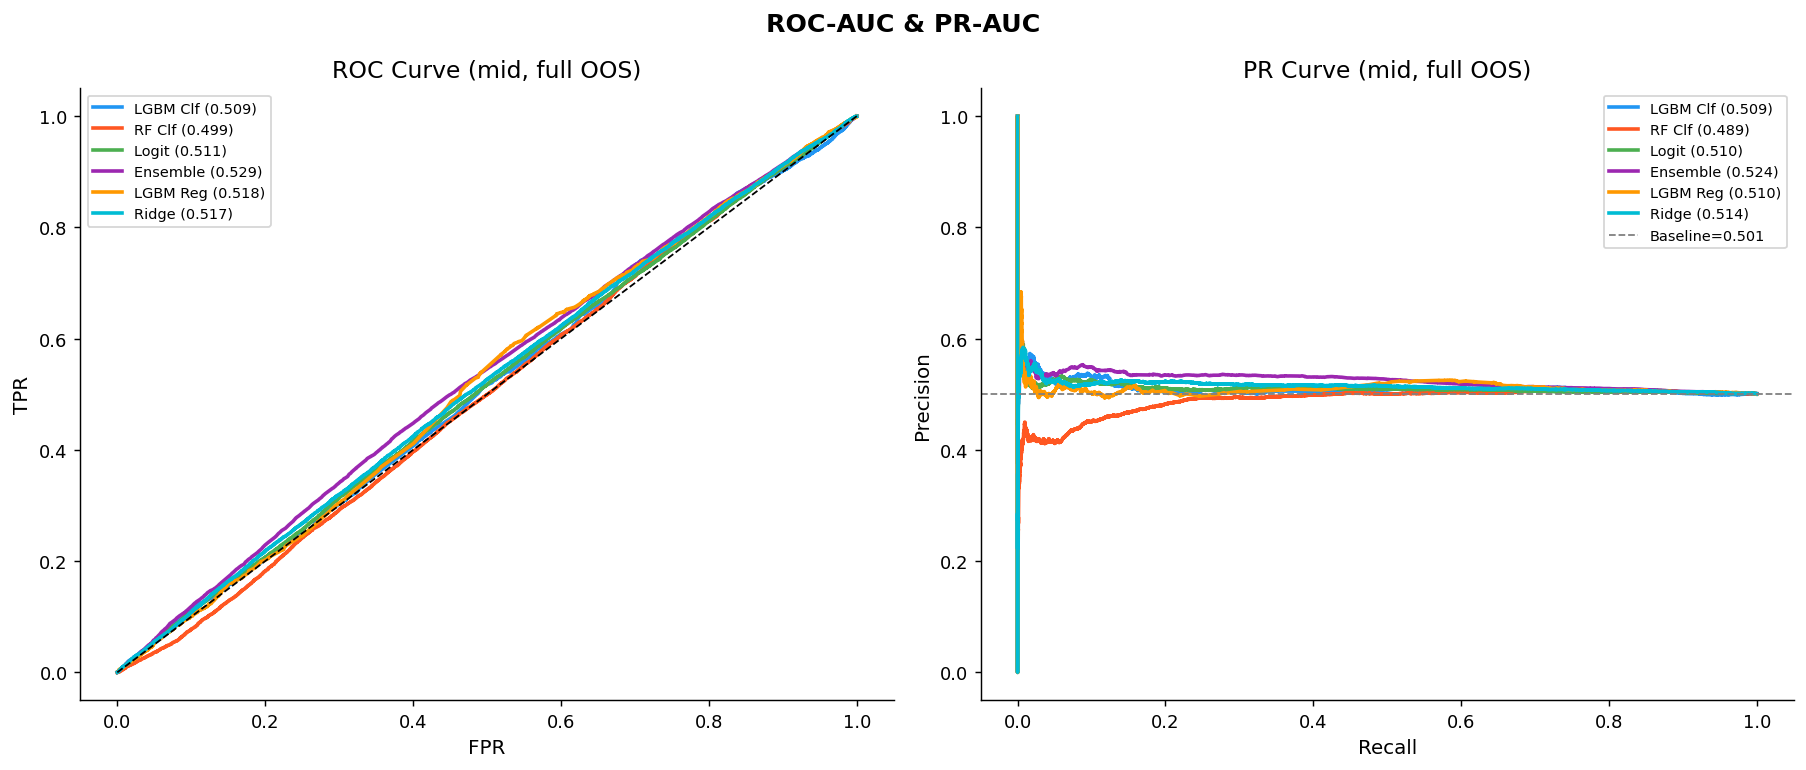

In [14]:
"""4.1 ROC and PR curves"""
hz = "mid"; tc = f"outperform_{hz}"
PMOD = [
    ("lgbm_clf",True,"LGBM Clf"),("rf_clf",True,"RF Clf"),
    ("logit",True,"Logit"),("ens_rank4",False,"Ensemble"),
    ("lgbm_reg",False,"LGBM Reg"),("ridge",False,"Ridge"),
]
fig, (ax_roc,ax_pr) = plt.subplots(1,2,figsize=(14,6))
for i,(mk,up,lab) in enumerate(PMOD):
    key = f"{mk}_{hz}"
    if key not in OOS_DICT: continue
    df = OOS_DICT[key].dropna(subset=[tc])
    y  = df[tc].astype(int).values
    s  = (df["pred_prob"].fillna(0.5).values if up and "pred_prob" in df
          else df["pred_score"].rank(pct=True).values)
    if y.sum()==0: continue
    fpr,tpr,_ = roc_curve(y,s)
    pre,rec,_ = precision_recall_curve(y,s)
    auc_v = roc_auc_score(y,s)
    pr_v  = average_precision_score(y,s)
    ax_roc.plot(fpr,tpr,color=PALETTE[i],lw=2,label=f"{lab} ({auc_v:.3f})")
    ax_pr.plot(rec,pre,color=PALETTE[i],lw=2,label=f"{lab} ({pr_v:.3f})")
ax_roc.plot([0,1],[0,1],"k--",lw=1)
ax_roc.set(xlabel="FPR",ylabel="TPR",title="ROC Curve (mid, full OOS)")
ax_roc.legend(fontsize=8)
pos_r = float(OOS_DICT["ens_rank4_mid"][tc].mean())
ax_pr.axhline(pos_r,color="grey",ls="--",lw=1,label=f"Baseline={pos_r:.3f}")
ax_pr.set(xlabel="Recall",ylabel="Precision",title="PR Curve (mid, full OOS)")
ax_pr.legend(fontsize=8)
plt.suptitle("ROC-AUC & PR-AUC",fontsize=14,fontweight="bold")
plt.tight_layout(); plt.show()

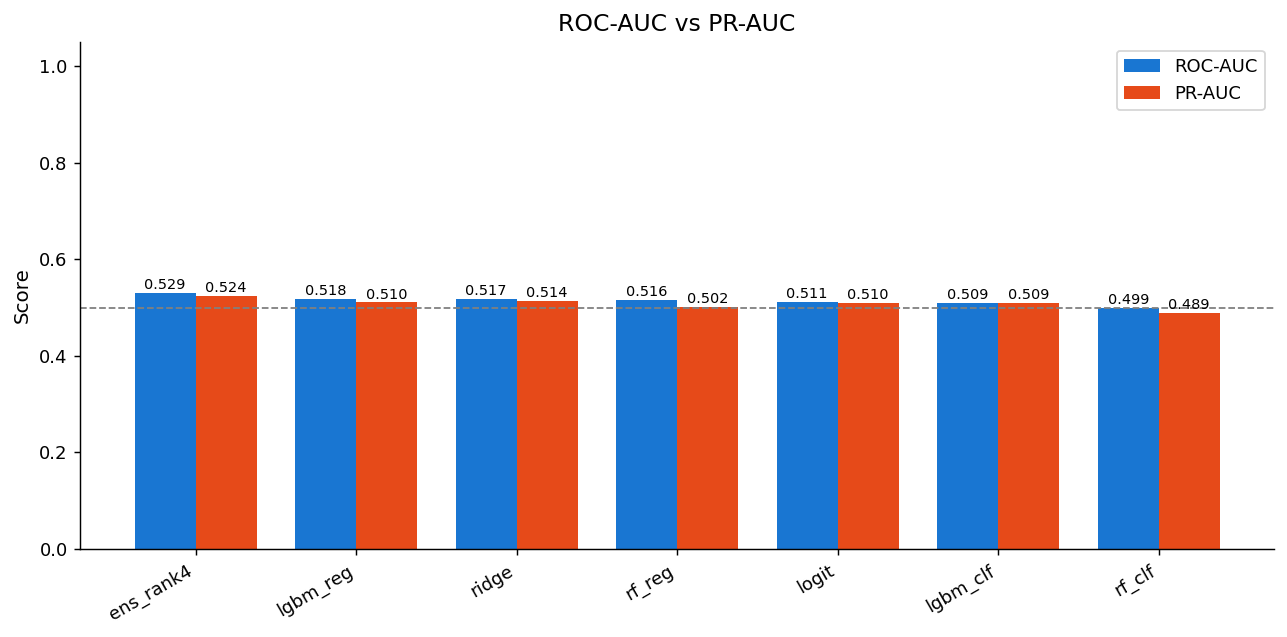

In [15]:
"""4.2 AUC / PR-AUC bar comparison"""
a_s = CLF_DF["ROC-AUC"].sort_values(ascending=False)
p_s = CLF_DF["PR-AUC"].reindex(a_s.index)
x = np.arange(len(a_s)); w = 0.38
fig, ax = plt.subplots(figsize=(10,5))
b1 = ax.bar(x-w/2,a_s.values,w,label="ROC-AUC",color="#1976D2")
b2 = ax.bar(x+w/2,p_s.values,w,label="PR-AUC", color="#E64A19")
ax.axhline(0.5,color="grey",ls="--",lw=1)
ax.set_xticks(x); ax.set_xticklabels(a_s.index,rotation=30,ha="right")
ax.set(ylabel="Score",ylim=(0,1.05),title="ROC-AUC vs PR-AUC")
ax.legend()
for b in list(b1)+list(b2):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()+0.008,
            f"{b.get_height():.3f}",ha="center",fontsize=8)
plt.tight_layout(); plt.show()

---
## 5. Regression Metrics (MAE, MSE) & Predicted vs. Actual Analysis

In [16]:
"""5.1 Compute MAE/MSE from OOS frames"""
reg_records = []
for mk in ("ens_rank4","lgbm_reg","rf_reg","ridge","lgbm_clf","rf_clf","momentum_126","lstm_reg"):
    for hz in ("short","mid","long"):
        key = f"{mk}_{hz}"
        if key not in OOS_DICT: continue
        df = OOS_DICT[key].dropna(subset=[f"fwd_ret_{hz}","pred_score"])
        if df.empty: continue
        ps = df.groupby("Date")["pred_score"].rank(pct=True)
        trk = f"fwd_rankpct_{hz}"
        tr  = df[trk] if trk in df.columns else ps*0+0.5
        reg_records.append({
            "Model":mk,"Horizon":hz,
            "MAE (rank)":  mean_absolute_error(tr,ps),
            "MSE (rank)":  mean_squared_error(tr,ps),
            "RMSE (rank)": mean_squared_error(tr,ps)**0.5,
            "MAE (return)": mean_absolute_error(df[f"fwd_ret_{hz}"],df["pred_score"]),
            "MSE (return)": mean_squared_error(df[f"fwd_ret_{hz}"],df["pred_score"]),
        })
REG_DF = pd.DataFrame(reg_records)
display(show_styled(REG_DF.pivot_table(index="Model",columns="Horizon",values="MAE (rank)").round(4),\
                    caption="MAE on rank-percentile (lower = better)",cmap="RdYlGn_r",axis=None))

=== MAE on rank-percentile (lower = better) ===


Horizon,long,mid,short
Model,,,
ens_rank4,0.3113,0.3173,0.3230
lgbm_clf,NaN,0.3231,NaN
lgbm_reg,0.3024,0.3161,0.3176
lstm_reg,NaN,0.3332,NaN
momentum_126,NaN,0.3174,NaN
rf_clf,NaN,0.3278,NaN
rf_reg,NaN,0.3211,NaN
ridge,0.3174,0.3228,0.3233


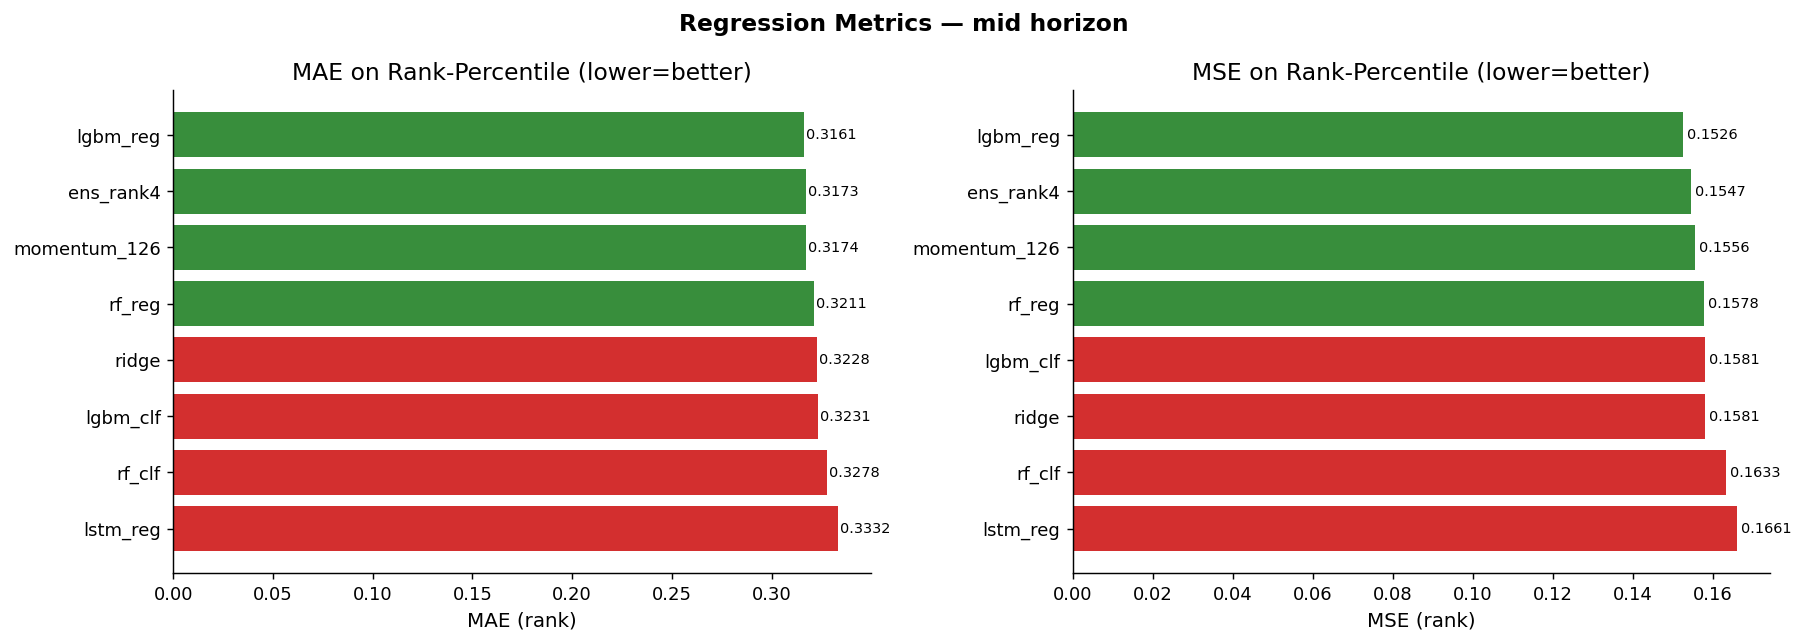

In [17]:
"""5.2 MAE/MSE bar chart (mid horizon)"""
hz = "mid"
sub_r = REG_DF[REG_DF["Horizon"]==hz].set_index("Model")
fig, axes = plt.subplots(1,2,figsize=(14,5))
for ax,(col,ttl) in zip(axes,[
    ("MAE (rank)","MAE on Rank-Percentile (lower=better)"),
    ("MSE (rank)","MSE on Rank-Percentile (lower=better)"),
]):
    vals = sub_r[col].sort_values()
    clrs = ["#D32F2F" if v>vals.median() else "#388E3C" for v in vals]
    ax.barh(vals.index[::-1],vals.values[::-1],color=clrs[::-1])
    for p,v in zip(ax.patches,vals.values[::-1]):
        ax.text(v+0.001,p.get_y()+p.get_height()/2,f"{v:.4f}",va="center",fontsize=8)
    ax.set_title(ttl); ax.set_xlabel(col)
plt.suptitle(f"Regression Metrics — {hz} horizon",fontsize=13,fontweight="bold")
plt.tight_layout(); plt.show()

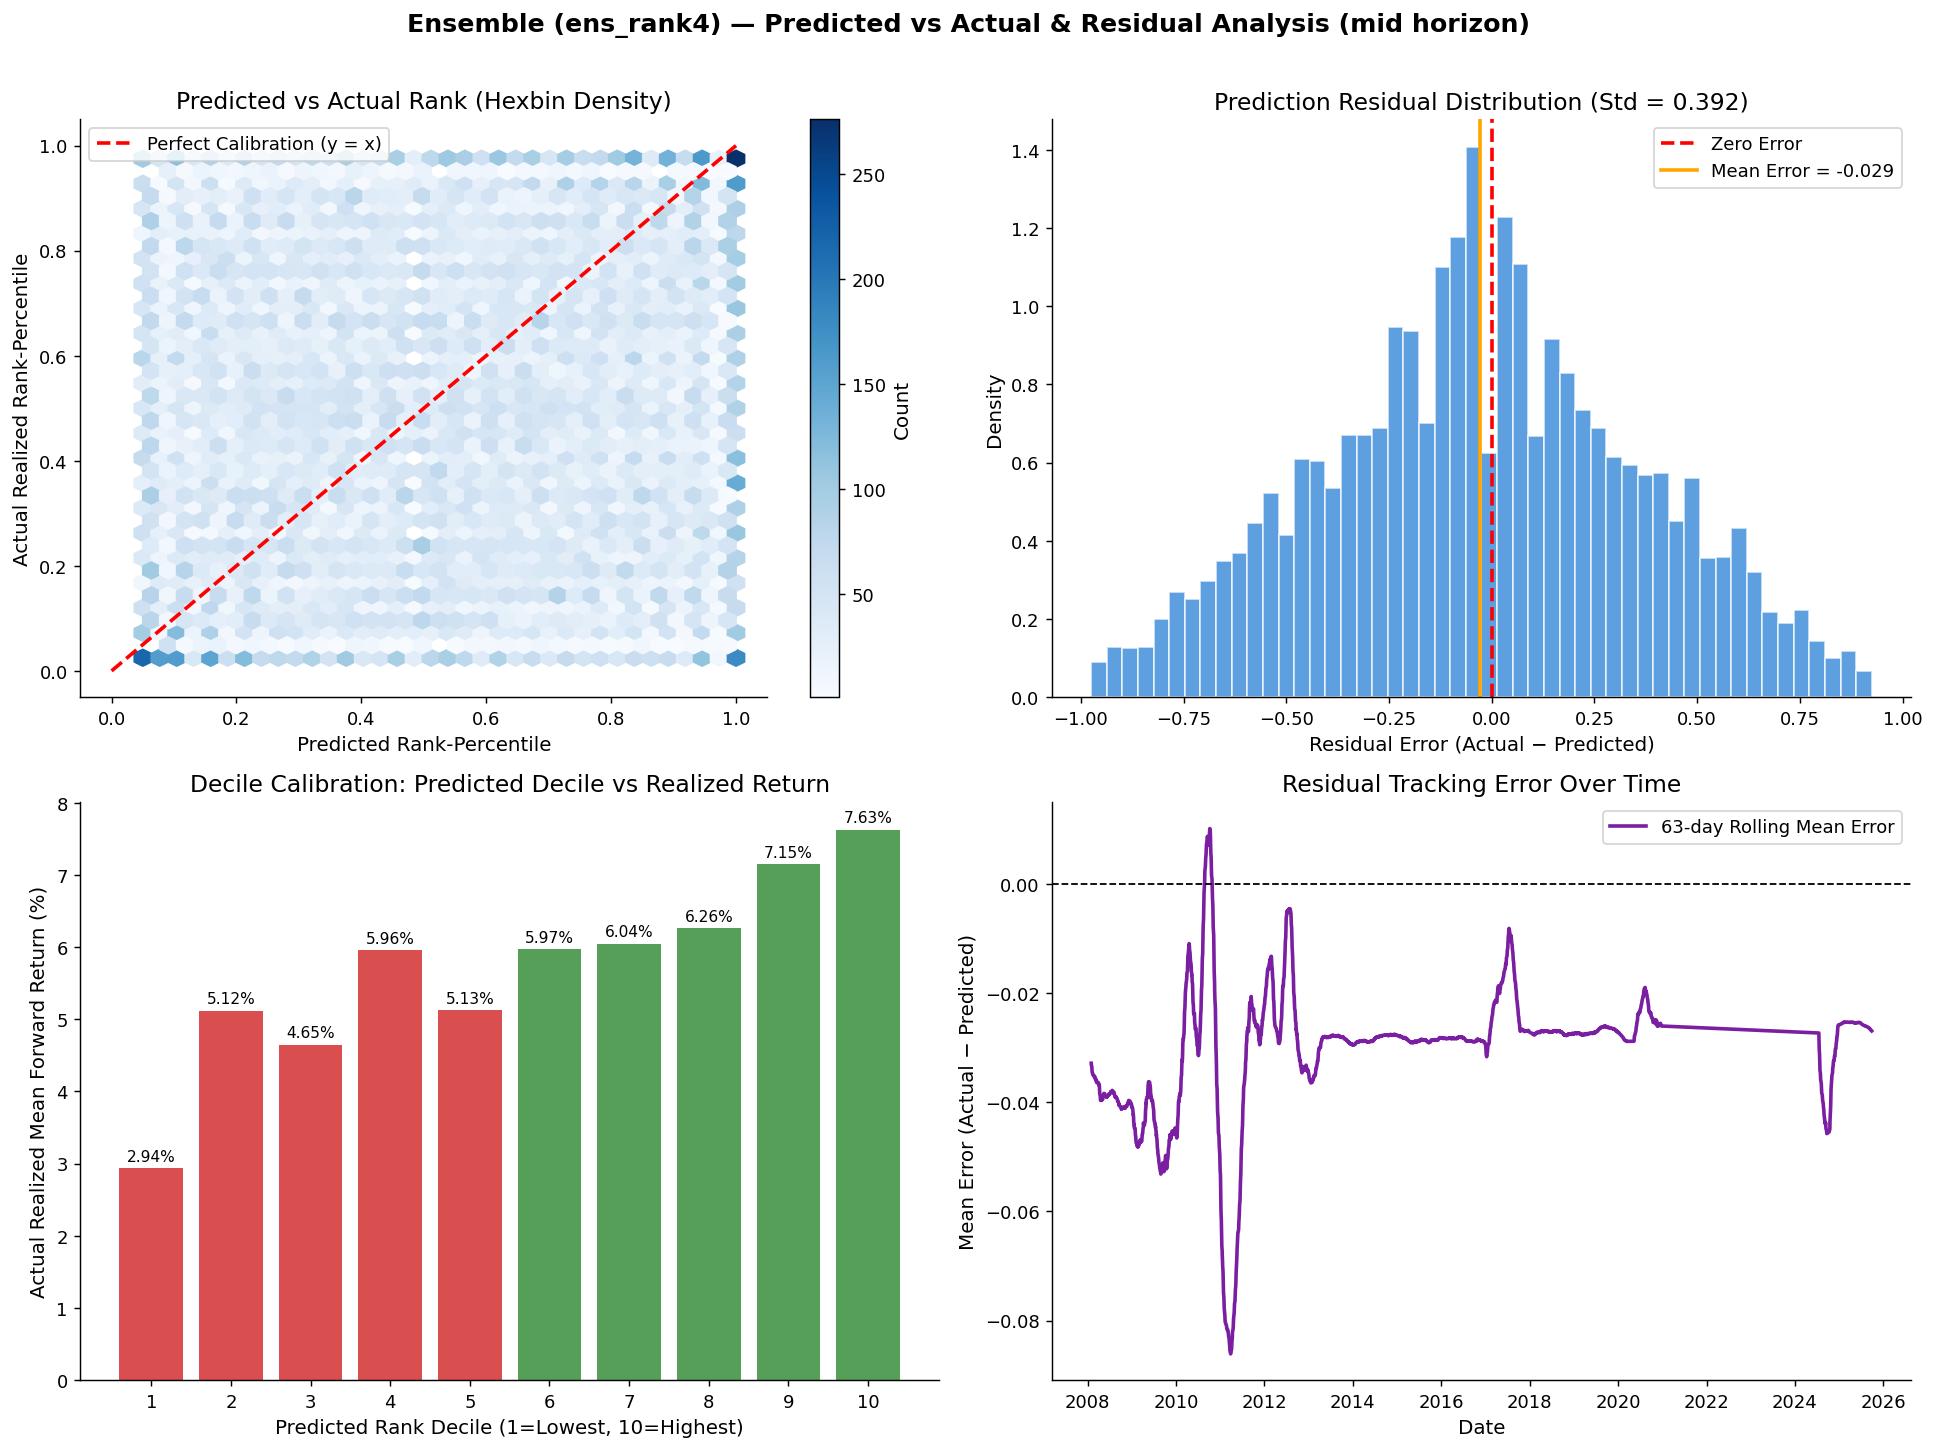

In [18]:
"""5.3 Predicted vs Actual & Residual Analysis (Ensemble, mid horizon)"""
if "ens_rank4_mid" in OOS_DICT:
    df = OOS_DICT["ens_rank4_mid"].dropna(subset=["fwd_rankpct_mid","pred_score"]).copy()
    df["pred_rankpct"] = df.groupby("Date")["pred_score"].rank(pct=True)
    df["error"] = df["fwd_rankpct_mid"] - df["pred_rankpct"]
    fig, axes = plt.subplots(2,2,figsize=(15,11))
    # 1. Hexbin density: Predicted vs Actual
    ax1 = axes[0,0]
    hb = ax1.hexbin(df["pred_rankpct"],df["fwd_rankpct_mid"],gridsize=35,cmap="Blues",mincnt=1)
    ax1.plot([0,1],[0,1],"r--",lw=2,label="Perfect Calibration (y = x)")
    ax1.set(xlabel="Predicted Rank-Percentile",ylabel="Actual Realized Rank-Percentile",
            title="Predicted vs Actual Rank (Hexbin Density)")
    ax1.legend(loc="upper left")
    plt.colorbar(hb,ax=ax1,label="Count")
    # 2. Residual Error Distribution
    ax2 = axes[0,1]
    ax2.hist(df["error"],bins=50,color="#1976D2",alpha=0.7,density=True,edgecolor="white")
    ax2.axvline(0,color="red",ls="--",lw=2,label="Zero Error")
    mean_err = df["error"].mean(); std_err = df["error"].std()
    ax2.axvline(mean_err,color="orange",ls="-",lw=2,label=f"Mean Error = {mean_err:.3f}")
    ax2.set(xlabel="Residual Error (Actual − Predicted)",ylabel="Density",
            title=f"Prediction Residual Distribution (Std = {std_err:.3f})")
    ax2.legend()
    # 3. Decile Calibration: Predicted Decile vs Realized Forward Return
    ax3 = axes[1,0]
    df["decile"] = pd.qcut(df["pred_rankpct"],10,labels=False)+1
    dec_ret = df.groupby("decile")["fwd_ret_mid"].mean()*100
    clrs = ["#D32F2F" if r<dec_ret.median() else "#388E3C" for r in dec_ret]
    ax3.bar(dec_ret.index,dec_ret.values,color=clrs,alpha=0.85)
    ax3.set_xticks(range(1,11))
    ax3.set(xlabel="Predicted Rank Decile (1=Lowest, 10=Highest)",
            ylabel="Actual Realized Mean Forward Return (%)",
            title="Decile Calibration: Predicted Decile vs Realized Return")
    for i,v in enumerate(dec_ret):
        ax3.text(i+1,v+0.1,f"{v:.2f}%",ha="center",fontsize=8.5)
    # 4. Residual Tracking Error Over Time
    ax4 = axes[1,1]
    daily_err = df.groupby("Date")["error"].mean()
    ax4.plot(daily_err.index,daily_err.rolling(63,min_periods=20).mean(),color="#7B1FA2",lw=2,label="63-day Rolling Mean Error")
    ax4.axhline(0,color="black",ls="--",lw=1)
    ax4.set(xlabel="Date",ylabel="Mean Error (Actual − Predicted)",title="Residual Tracking Error Over Time")
    ax4.legend()
    plt.suptitle("Ensemble (ens_rank4) — Predicted vs Actual & Residual Analysis (mid horizon)",fontsize=14,fontweight="bold",y=1.01)
    plt.tight_layout(); plt.show()

---
## 6. Overfitting / Underfitting / Generalisation Gap

In [19]:
"""6.1 Dev vs Holdout IC gap table"""
gap_rows = []
for hz in HORIZONS:
    for m in ALL_MODELS:
        dev = RESULTS[
            (RESULTS["model"]==m)&(RESULTS["horizon"]==hz)&
            (RESULTS["split_type"]=="dev")&(RESULTS["metric"]=="rank_ic_mean")
        ]["value"].mean()
        hold = RESULTS[
            (RESULTS["model"]==m)&(RESULTS["horizon"]==hz)&
            (RESULTS["split_type"]=="holdout")&(RESULTS["metric"]=="rank_ic_mean")
        ]["value"].mean()
        if not (dev!=dev): # not nan
            gap_rows.append({"Model":m,"Horizon":hz,
                             "Dev IC":dev,"Holdout IC":hold,
                             "Gap":dev-hold,"Gap%":(dev-hold)/(abs(dev)+1e-9)*100})
GAP_DF = pd.DataFrame(gap_rows)
mid_gap = GAP_DF[GAP_DF["Horizon"]=="mid"].set_index("Model").sort_values("Gap")
mid_gap[["Dev IC","Holdout IC","Gap","Gap%"]].round(4)

,Dev IC,Holdout IC,Gap,Gap%
Model,,,,
ridge,0.0118,0.4149,-0.4031,-3404.4794
logit,0.0002,0.3606,-0.3604,-237646.0622
rf_clf,-0.0084,0.2972,-0.3056,-3623.2399
ens_rank4,0.0432,0.3176,-0.2743,-634.5810
ens_rank4_bestlgbm,0.0432,0.3176,-0.2743,-634.5810
rf_reg,0.0109,0.2166,-0.2057,-1878.7481
lgbm_reg,-0.0007,0.1948,-0.1955,-28101.3698
tabpfn_reg,0.0054,0.1980,-0.1926,-3582.7113
tabpfn_clf,0.0250,0.2010,-0.1760,-702.7721


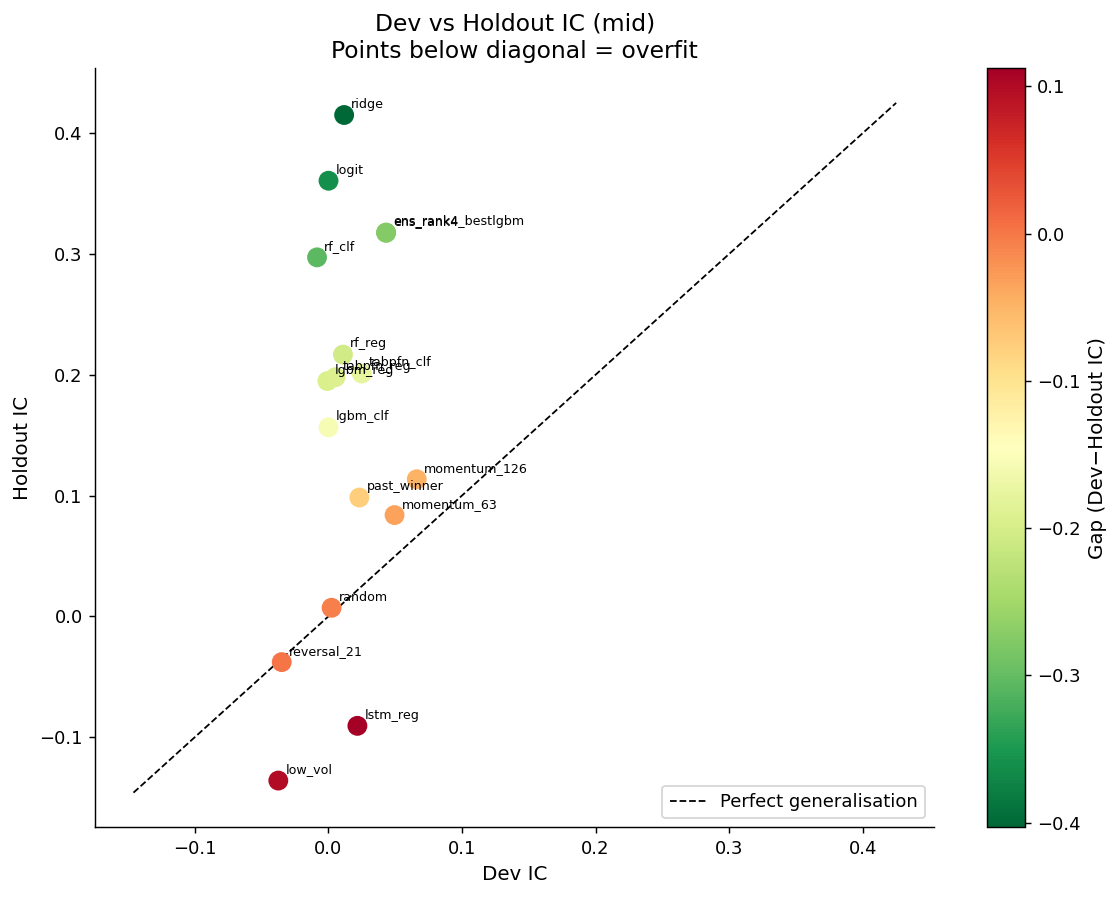

In [20]:
"""6.2 Scatter: Dev IC vs Holdout IC (colour = gap magnitude)"""
hz = "mid"
sub = GAP_DF[(GAP_DF["Horizon"]==hz)].dropna(subset=["Holdout IC"])
fig, ax = plt.subplots(figsize=(9,7))
sc = ax.scatter(sub["Dev IC"],sub["Holdout IC"],c=sub["Gap"],
                cmap="RdYlGn_r",s=100,zorder=3)
plt.colorbar(sc,ax=ax,label="Gap (Dev−Holdout IC)")
for _,row in sub.iterrows():
    ax.annotate(row["Model"],(row["Dev IC"],row["Holdout IC"]),
                fontsize=7,textcoords="offset points",xytext=(4,4))
lim = [min(sub["Dev IC"].min(),sub["Holdout IC"].min())-0.01,
       max(sub["Dev IC"].max(),sub["Holdout IC"].max())+0.01]
ax.plot(lim,lim,"k--",lw=1,label="Perfect generalisation")
ax.set(xlabel="Dev IC",ylabel="Holdout IC",
       title=f"Dev vs Holdout IC ({hz})\nPoints below diagonal = overfit")
ax.legend(); plt.tight_layout(); plt.show()

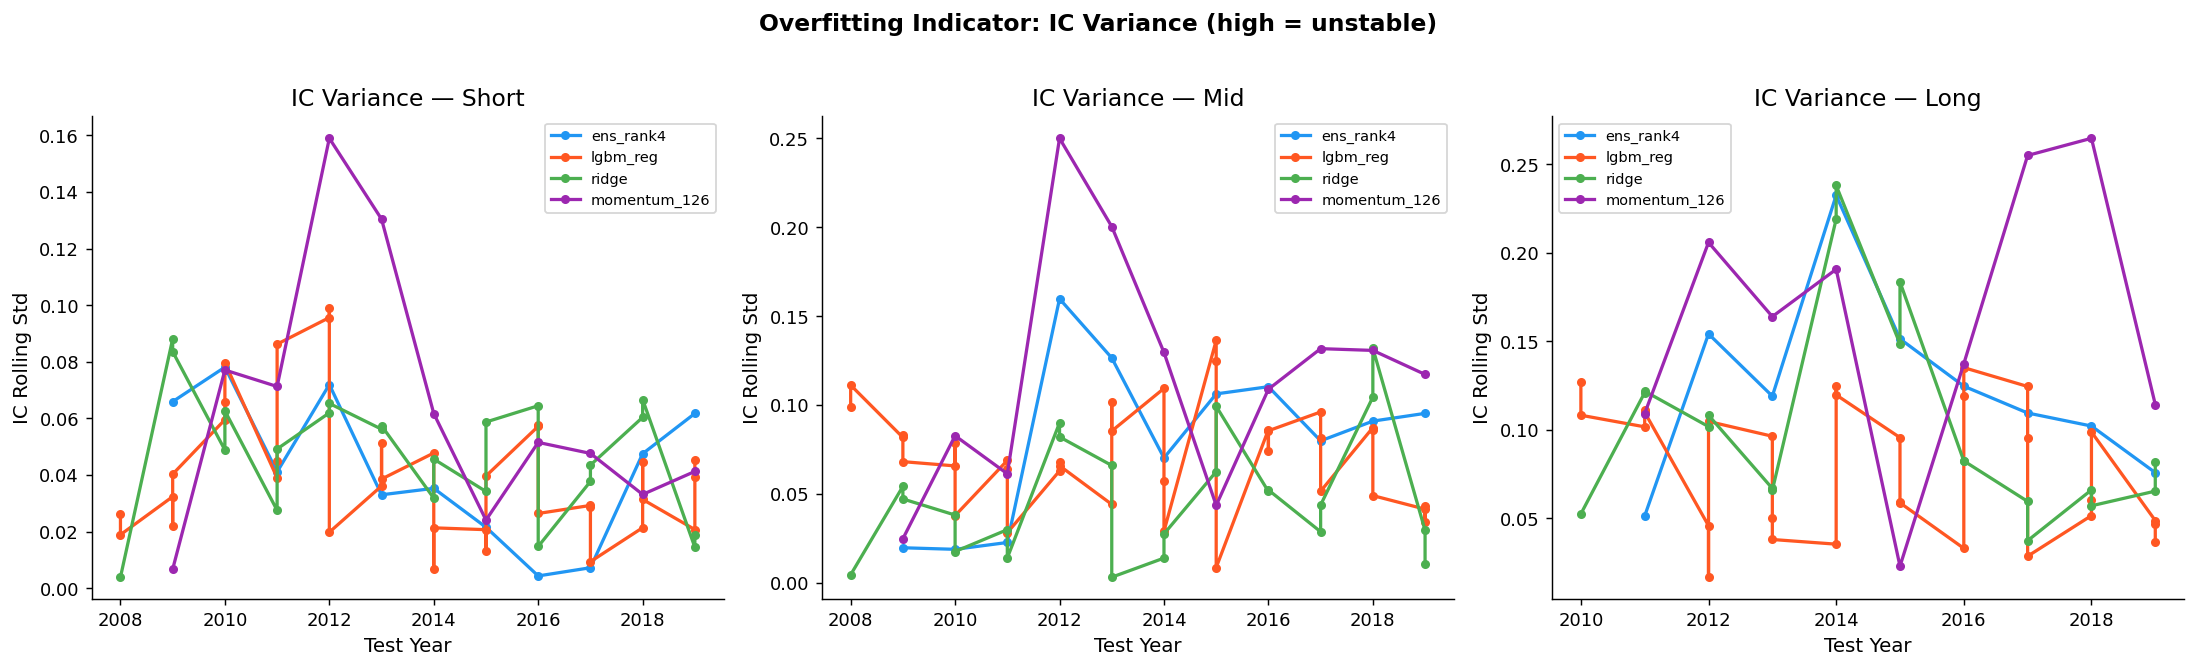

In [21]:
"""6.3 IC variance over folds (instability/overfit proxy)"""
fig, axes = plt.subplots(1,3,figsize=(17,5))
for ax, hz in zip(axes,HORIZONS):
    for i,m in enumerate(["ens_rank4","lgbm_reg","ridge","momentum_126"]):
        sub = RESULTS[
            (RESULTS["model"]==m)&(RESULTS["horizon"]==hz)&
            (RESULTS["split_type"]=="dev")&(RESULTS["metric"]=="rank_ic_mean")
        ].copy()
        sub = sub[sub["fold"].str.startswith("dev_")].copy()
        if sub.empty: continue
        sub["year"] = sub["fold"].str.extract(r"(\d{4})")[0].astype(int)
        sub = sub.sort_values("year")
        ax.plot(sub["year"],sub["value"].rolling(3,min_periods=1).std(),
                marker="o",ms=4,label=m,color=PALETTE[i],lw=1.8)
    ax.set_title(f"IC Variance — {hz.capitalize()}")
    ax.set_xlabel("Test Year"); ax.set_ylabel("IC Rolling Std")
    ax.legend(fontsize=8)
plt.suptitle("Overfitting Indicator: IC Variance (high = unstable)",
             fontsize=13,fontweight="bold",y=1.02)
plt.tight_layout(); plt.show()

---
## 7. Cross-Validation — Walk-Forward IC Summary

In [22]:
"""7.1 Fold summary CSV"""
try:
    folds_df = pd.read_csv(REP / "folds.csv")
    print(f"Fold summary: {folds_df.shape}")
    display(folds_df.head(10))
except FileNotFoundError:
    print("folds.csv not found"); folds_df = pd.DataFrame()

Fold summary: (39, 11)


,horizon,fold_name,split_type,train_start,train_end,rows_after_purge,test_start,test_end,test_rows,avg_rankable_stocks,num_test_dates
0,short,dev_2008,dev,2002-01-02,2007-11-21,16881,2008-01-02,2008-12-31,3111,13.07,238
1,short,dev_2009,dev,2002-01-02,2008-11-19,20041,2009-01-02,2009-12-30,3215,13.40,240
2,short,dev_2010,dev,2002-01-02,2009-11-20,23208,2010-01-04,2010-12-31,3777,15.87,238
3,short,dev_2011,dev,2002-01-02,2010-11-24,26956,2011-01-03,2011-12-30,3746,15.67,239
4,short,dev_2012,dev,2002-01-02,2011-11-23,30679,2012-01-02,2012-12-31,4159,17.19,242
5,short,dev_2013,dev,2002-01-02,2012-11-20,34815,2013-01-02,2013-12-31,4291,17.73,242
6,short,dev_2014,dev,2002-01-02,2013-11-21,39102,2014-01-02,2014-12-31,4301,17.85,241
7,short,dev_2015,dev,2002-01-02,2014-11-24,43406,2015-01-02,2015-12-31,4202,17.58,239
8,short,dev_2016,dev,2002-01-02,2015-11-20,47603,2016-01-04,2016-12-30,4206,17.52,240
9,short,dev_2017,dev,2002-01-02,2016-11-21,51815,2017-01-02,2017-12-29,4507,18.70,241


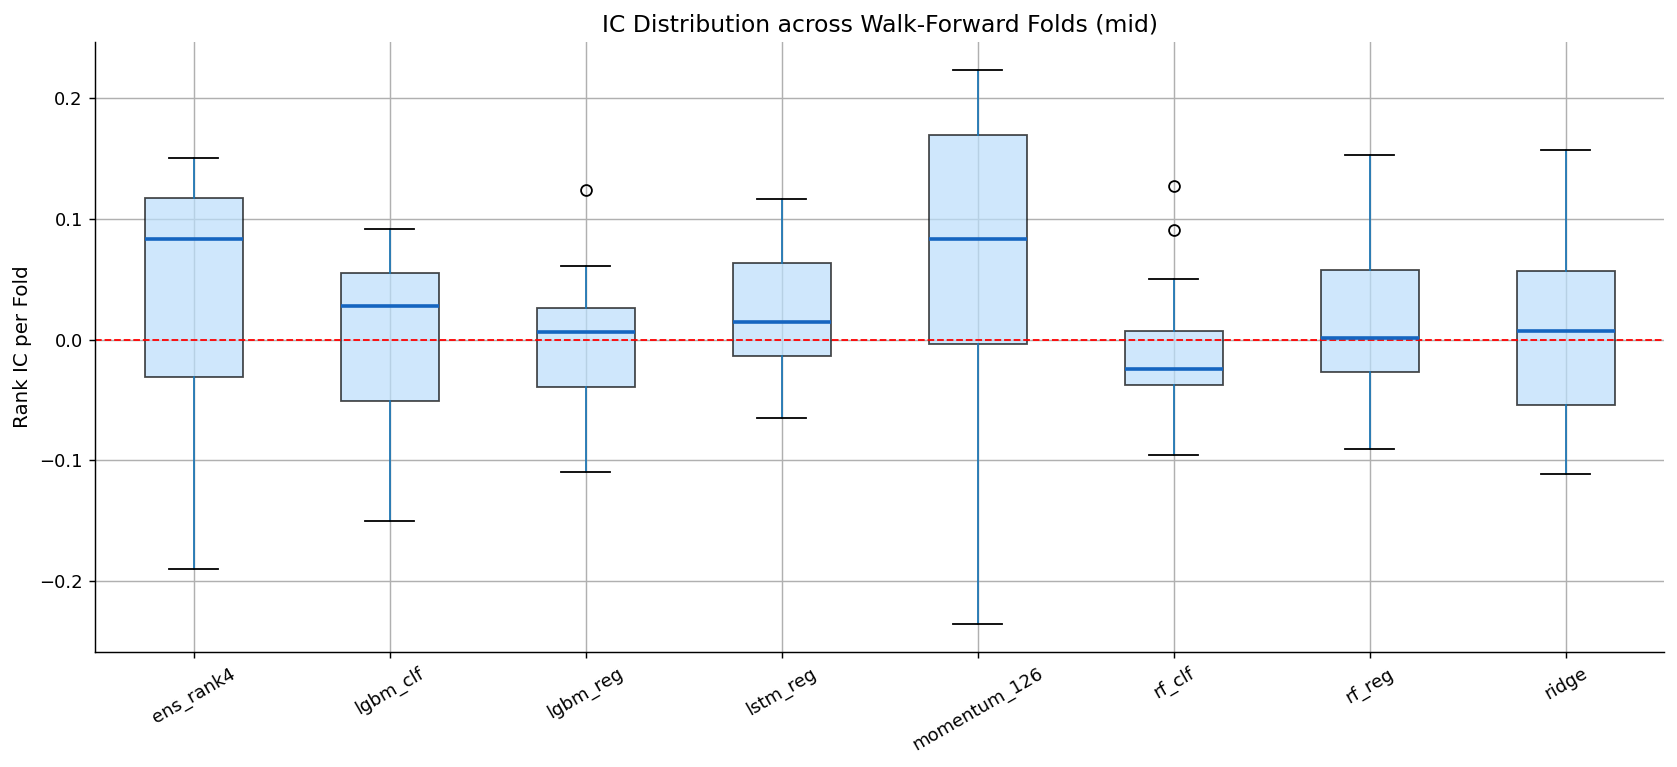

In [23]:
"""7.2 IC distribution per fold (boxplot)"""
ic_pivot = RESULTS[
    (RESULTS["horizon"]=="mid")&(RESULTS["split_type"]=="dev")&
    (RESULTS["metric"]=="rank_ic_mean")&(RESULTS["model"].isin(PRIMARY_MODELS))
].pivot_table(index="fold",columns="model",values="value")
ic_pivot = ic_pivot[ic_pivot.index.str.startswith("dev_")].copy()
if not ic_pivot.empty:
    ic_pivot["yr"] = ic_pivot.index.str.extract(r"(\d{4})")[0].astype(int)
    ic_pivot = ic_pivot.sort_values("yr").drop(columns="yr")
    fig, ax = plt.subplots(figsize=(13,6))
    ic_pivot.boxplot(ax=ax,vert=True,patch_artist=True,
                     boxprops=dict(facecolor="#BBDEFB",alpha=0.7),
                     medianprops=dict(color="#1565C0",lw=2))
    ax.axhline(0,color="red",ls="--",lw=1)
    ax.set_title("IC Distribution across Walk-Forward Folds (mid)")
    ax.set_ylabel("Rank IC per Fold")
    ax.tick_params(axis="x",rotation=30)
    plt.tight_layout(); plt.show()

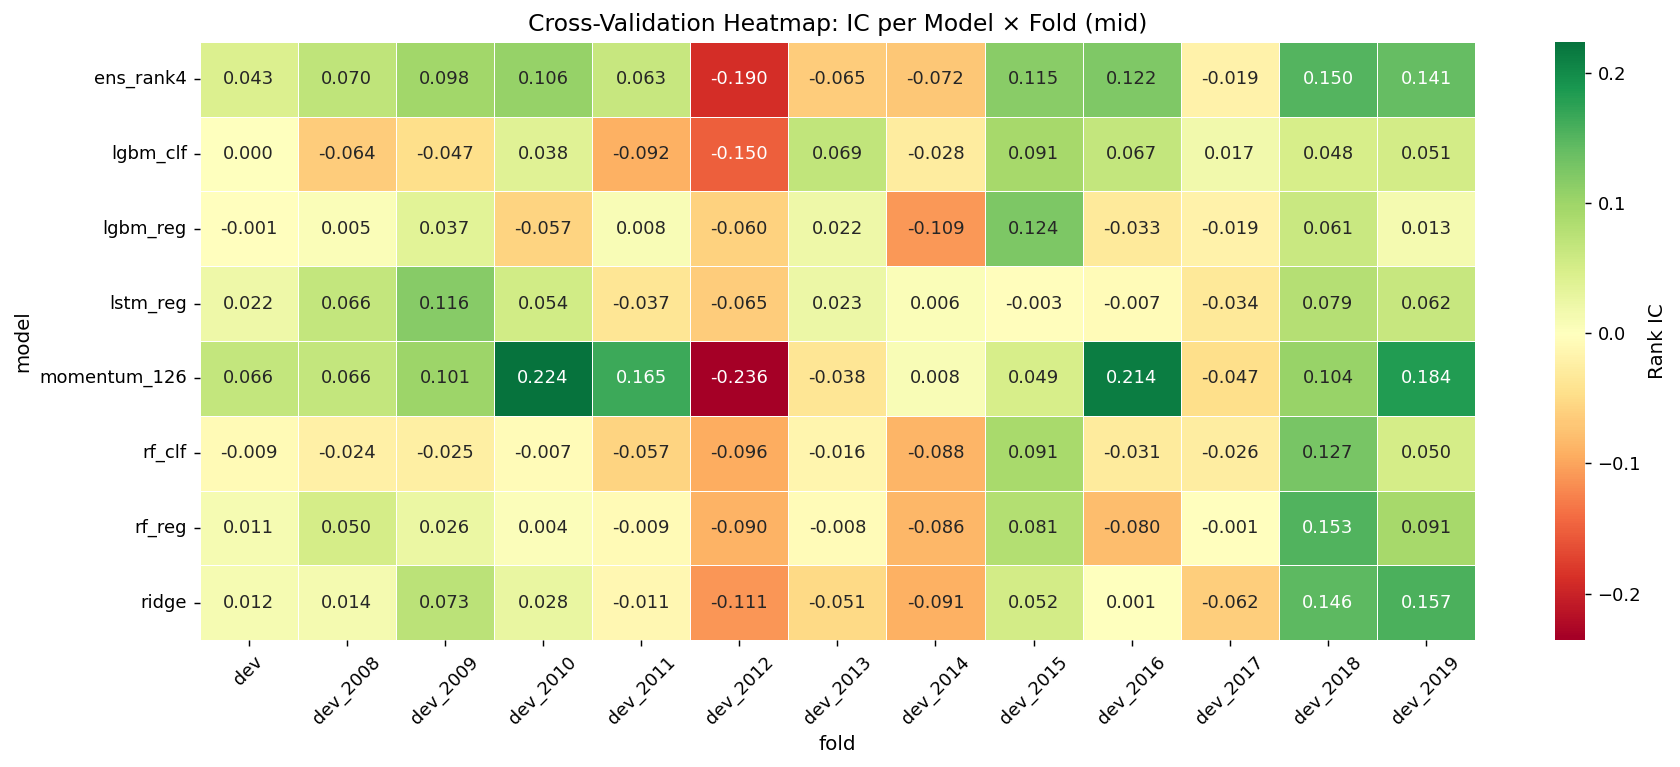

In [24]:
"""7.3 Model × Fold IC heatmap"""
ic_mat = RESULTS[
    (RESULTS["horizon"]=="mid")&(RESULTS["split_type"]=="dev")&
    (RESULTS["metric"]=="rank_ic_mean")&(RESULTS["model"].isin(PRIMARY_MODELS))
].pivot_table(index="model",columns="fold",values="value")
col_order = sorted(ic_mat.columns,
    key=lambda c: int(c.split("_")[1]) if "_" in c else 0)
ic_mat = ic_mat[col_order]
fig, ax = plt.subplots(figsize=(14,6))
sns.heatmap(ic_mat,annot=True,fmt=".3f",cmap="RdYlGn",center=0,
            linewidths=0.4,ax=ax,cbar_kws={"label":"Rank IC"})
ax.set_title("Cross-Validation Heatmap: IC per Model × Fold (mid)")
ax.tick_params(axis="x",rotation=45)
plt.tight_layout(); plt.show()

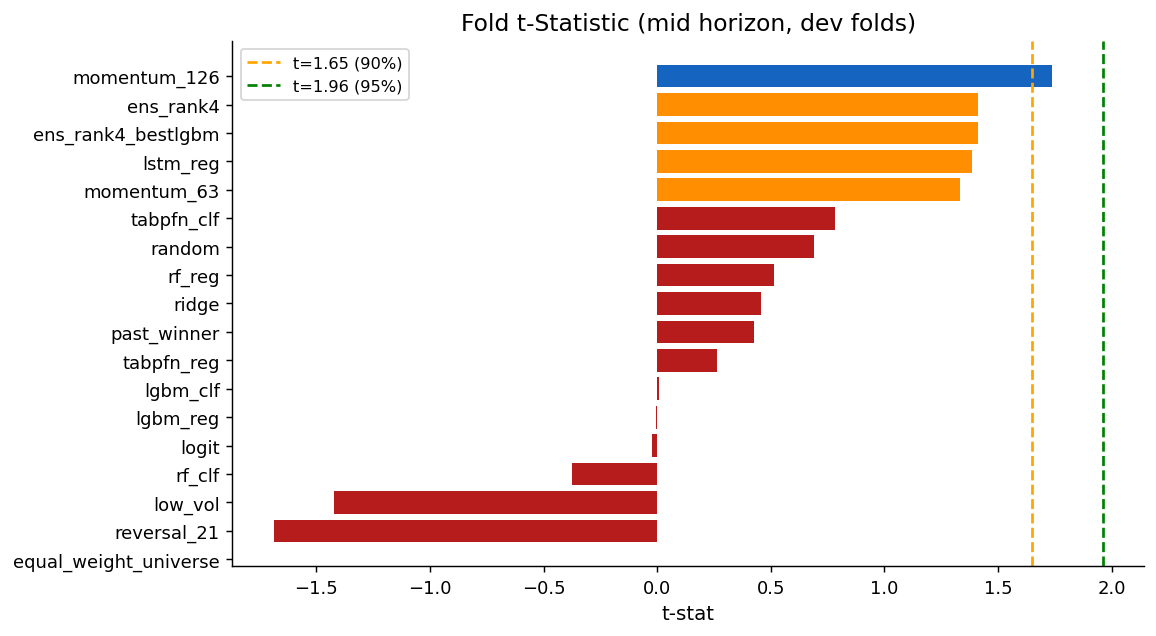

In [25]:
"""7.4 Fold t-statistic per model"""
ts = mean_metric("folds_t_stat","mid","dev")
fig, ax = plt.subplots(figsize=(9,5))
clrs = ["#1565C0" if v>1.65 else "#FF8F00" if v>1.28 else "#B71C1C" for v in ts.values]
ax.barh(ts.index[::-1],ts.values[::-1],color=clrs[::-1])
ax.axvline(1.65,color="orange",ls="--",lw=1.5,label="t=1.65 (90%)")
ax.axvline(1.96,color="green", ls="--",lw=1.5,label="t=1.96 (95%)")
ax.set_title("Fold t-Statistic (mid horizon, dev folds)")
ax.set_xlabel("t-stat"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## 8. Computational Efficiency

In [26]:
"""8.1 Parquet file sizes as model-complexity proxy"""
sz = pd.DataFrame([{"file":p.stem,"size_kb":p.stat().st_size/1024}
                   for p in sorted(OOS.glob("*.parquet"))])\
       .sort_values("size_kb",ascending=False)
display(sz.head(12))

,file,size_kb
28,logit_short_core,2168.278320
55,rf_clf_short_core,2167.434570
26,logit_mid_core,2154.040039
53,rf_clf_mid_core,2137.790039
29,logit_short_full,2075.257812
56,rf_clf_short_full,2073.804688
27,logit_mid_full,2058.022461
54,rf_clf_mid_full,2033.616211
13,lgbm_clf_short_core,1720.310547
70,tabpfn_clf_mid_core,1709.550781


,N rows,N dates,ms/date
Model,,,
Ensemble,55840,3374,1.350
LGBM Reg,55840,3374,1.193
RF Reg,55840,3374,1.134
Ridge,55840,3374,1.156
LGBM Clf,55840,3374,1.161
Momentum,55840,3374,1.093


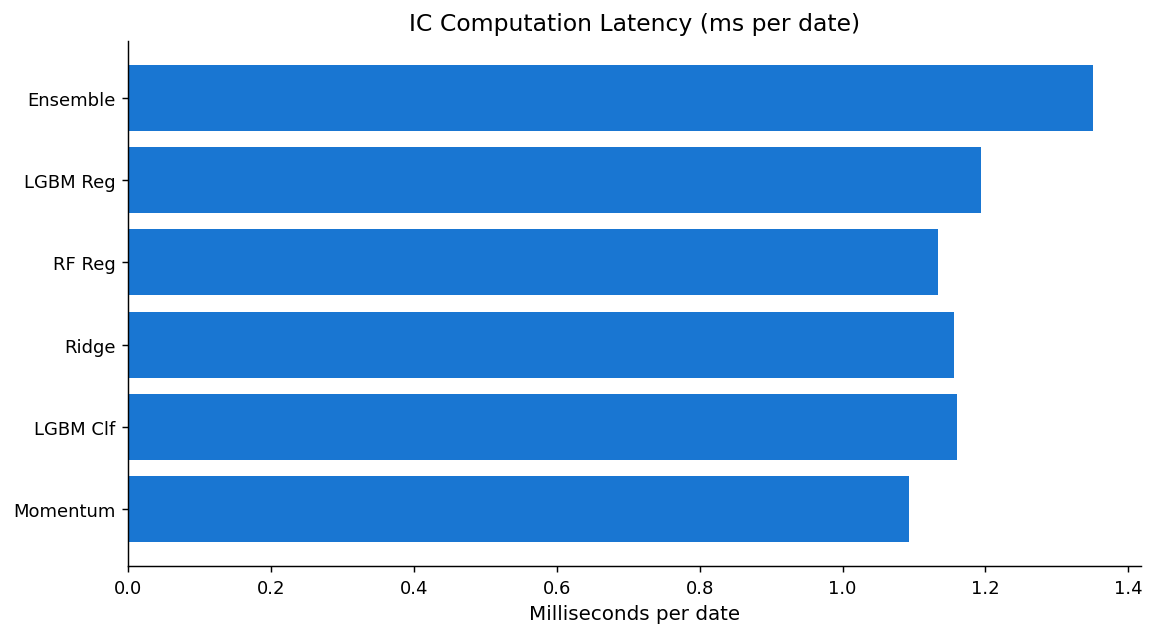

In [27]:
"""8.2 Scoring latency benchmark (Spearman IC per date)"""
tm_records = []
BENCH = [
    ("Ensemble","ens_rank4_mid"),("LGBM Reg","lgbm_reg_mid"),
    ("RF Reg","rf_reg_mid"),("Ridge","ridge_mid"),
    ("LGBM Clf","lgbm_clf_mid"),("Momentum","momentum_126_mid"),
]
for lab, key in BENCH:
    if key not in OOS_DICT: continue
    df = OOS_DICT[key]; hz = key.split("_")[-1]
    t0 = time.perf_counter(); n = 0
    for dt,grp in df.groupby("Date"):
        v = grp.dropna(subset=["pred_score",f"fwd_ret_{hz}"])
        if len(v)>=4: spearmanr(v["pred_score"],v[f"fwd_ret_{hz}"])
        n += 1
    ms = (time.perf_counter()-t0)/max(n,1)*1000
    tm_records.append({"Model":lab,"N rows":len(df),"N dates":df["Date"].nunique(),"ms/date":ms})

TM = pd.DataFrame(tm_records).set_index("Model")
display(TM.round(3))
fig, ax = plt.subplots(figsize=(9,5))
ax.barh(TM.index[::-1],TM["ms/date"].values[::-1],color="#1976D2")
ax.set_title("IC Computation Latency (ms per date)")
ax.set_xlabel("Milliseconds per date")
plt.tight_layout(); plt.show()

---
## 9. Class Imbalance Analysis

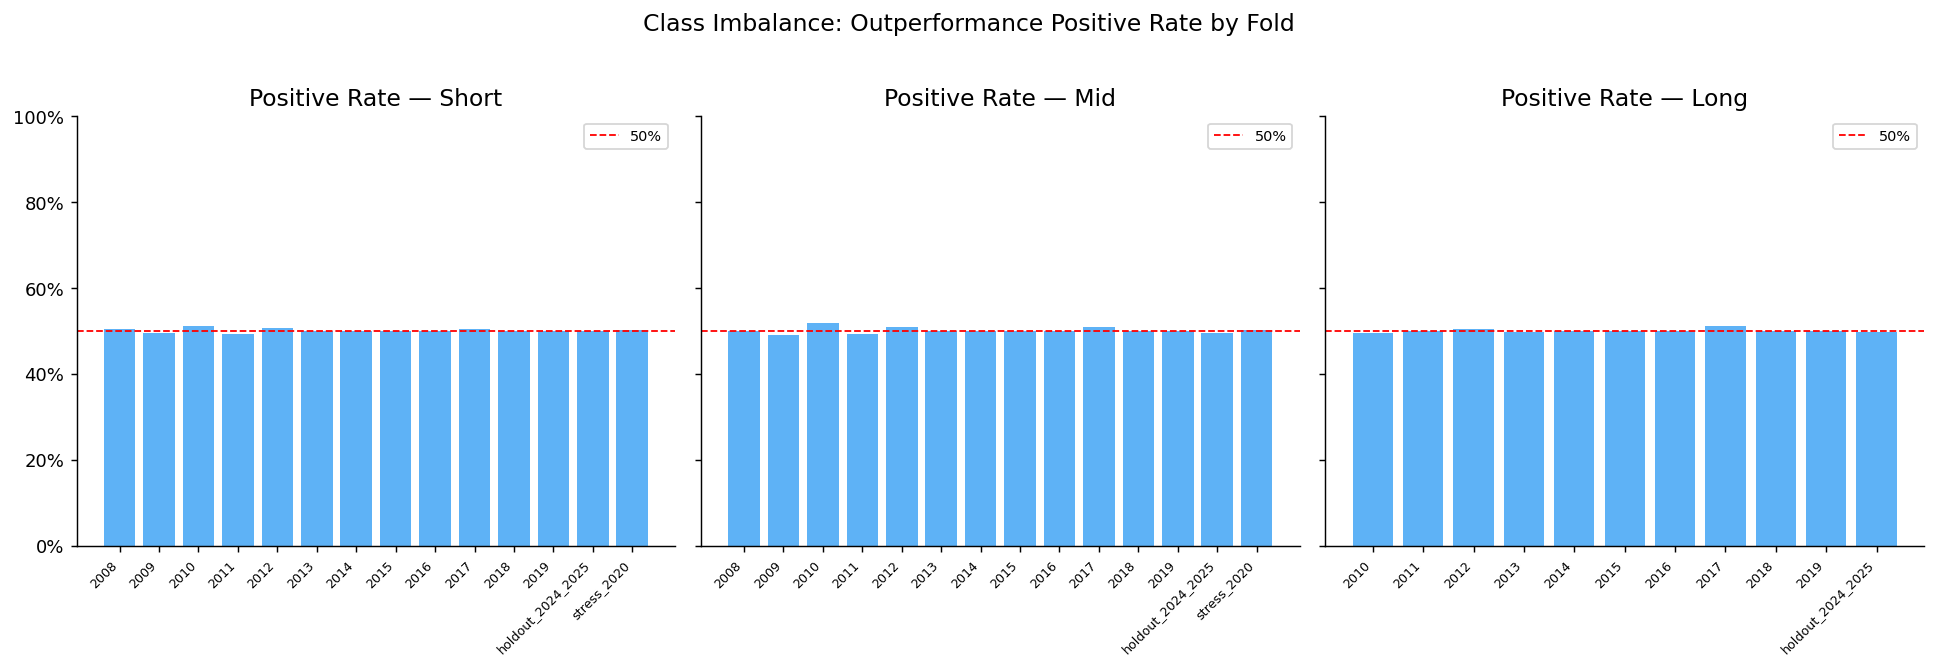

Overall positive rate: Horizon
long     0.5009
mid      0.5011
short    0.5011
Name: Pos Rate, dtype: float64


In [28]:
"""9.1 Positive-rate (outperformance) per fold"""
imb = []
for hz in ("short","mid","long"):
    key = f"ens_rank4_{hz}"
    if key not in OOS_DICT: continue
    df = OOS_DICT[key]; tc = f"outperform_{hz}"
    if tc not in df.columns: continue
    for fold,grp in df.groupby("fold"):
        v = grp[tc].dropna()
        if len(v)<10: continue
        imb.append({"Horizon":hz,"Fold":fold,"Pos Rate":v.mean(),"N":len(v)})

IMB = pd.DataFrame(imb)
fig, axes = plt.subplots(1,3,figsize=(15,5),sharey=True)
for ax, hz in zip(axes,HORIZONS):
    sub = IMB[IMB["Horizon"]==hz].sort_values("Fold")
    if sub.empty: continue
    ax.bar(range(len(sub)),sub["Pos Rate"],color="#42A5F5",alpha=0.85)
    ax.axhline(0.5,color="red",ls="--",lw=1,label="50%")
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub["Fold"].str.replace("dev_",""),rotation=45,ha="right",fontsize=7)
    ax.set_title(f"Positive Rate — {hz.capitalize()}")
    ax.set_ylim(0,1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(fontsize=8)
plt.suptitle("Class Imbalance: Outperformance Positive Rate by Fold",fontsize=13,y=1.02)
plt.tight_layout(); plt.show()
print("Overall positive rate:", IMB.groupby("Horizon")["Pos Rate"].mean().round(4))

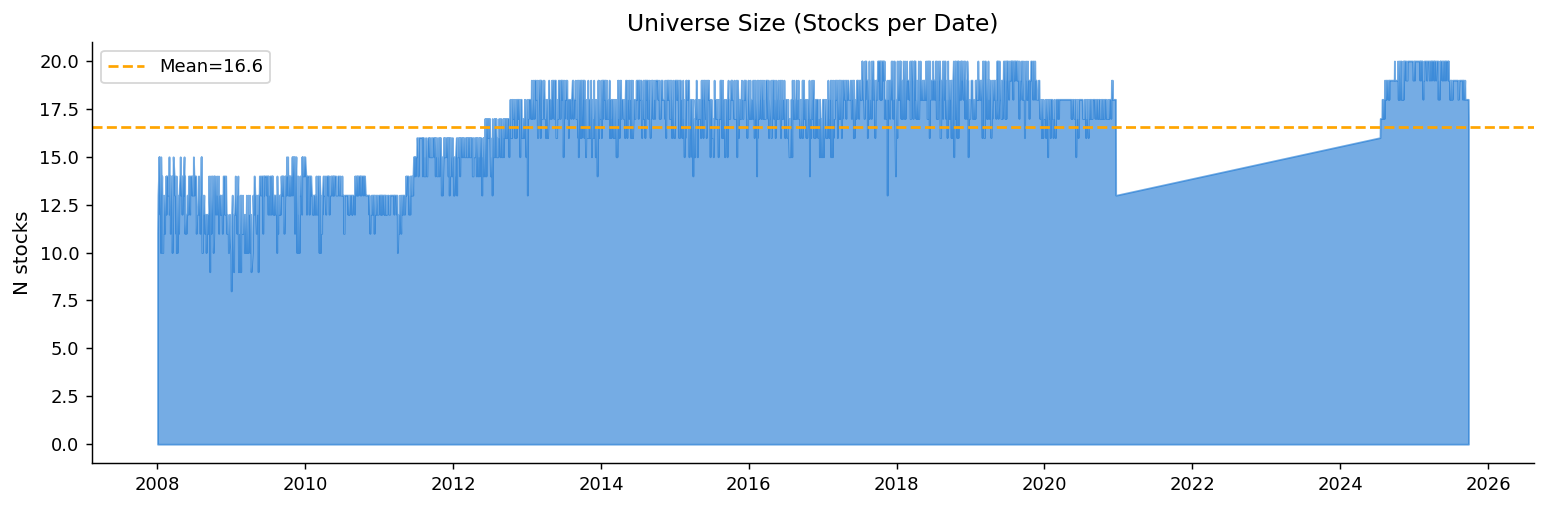

In [29]:
"""9.2 Universe size over time"""
if "ens_rank4_mid" in OOS_DICT:
    cs = OOS_DICT["ens_rank4_mid"].groupby("Date").size()
    fig, ax = plt.subplots(figsize=(12,4))
    ax.fill_between(cs.index,cs.values,alpha=0.6,color="#1976D2")
    ax.axhline(cs.mean(),color="orange",ls="--",lw=1.5,label=f"Mean={cs.mean():.1f}")
    ax.set_title("Universe Size (Stocks per Date)")
    ax.set_ylabel("N stocks"); ax.legend()
    plt.tight_layout(); plt.show()

---
## 10. Interpretability — Ridge Coefficients

In [30]:
"""10.1 Load Ridge coefficients"""
COEF = pd.read_csv(REP / "04_linear_coefficients.csv")
print(f"Shape: {COEF.shape}")
display(COEF.head(3))
FEATURE_LABELS = {
    "log_ret_5":"5d Ret","log_ret_10":"10d Ret","log_ret_21":"21d Ret",
    "log_ret_63":"63d Ret","log_ret_126":"126d Ret","log_ret_252":"252d Ret",
    "vol_21d":"21d Vol","vol_63d":"63d Vol","downside_vol_63d":"Downside Vol",
    "rsi_14":"RSI-14","macd_hist_norm":"MACD Hist","bollinger_pct_b_20":"Bollinger%B",
    "amihud_illiq_63d":"Amihud","zero_trade_share_63d":"Zero-Trade%",
    "rel_ret_21d":"RelRet 21d","rel_ret_63d":"RelRet 63d",
    "cs_rank_mom_63d":"CS Mom Rank","cs_rank_vol_63d":"CS Vol63",
    "cs_rank_vol_21d":"CS Vol21","index_ret_63d":"Idx Ret","index_vol_63d":"Idx Vol",
}

Shape: (4524, 7)


,model,feature_set,horizon,fold,split_type,feature,coefficient
0,ridge,core,short,dev_2008,dev,log_ret_5,-0.006003
1,ridge,core,short,dev_2008,dev,log_ret_10,0.000227
2,ridge,core,short,dev_2008,dev,log_ret_21,0.002576


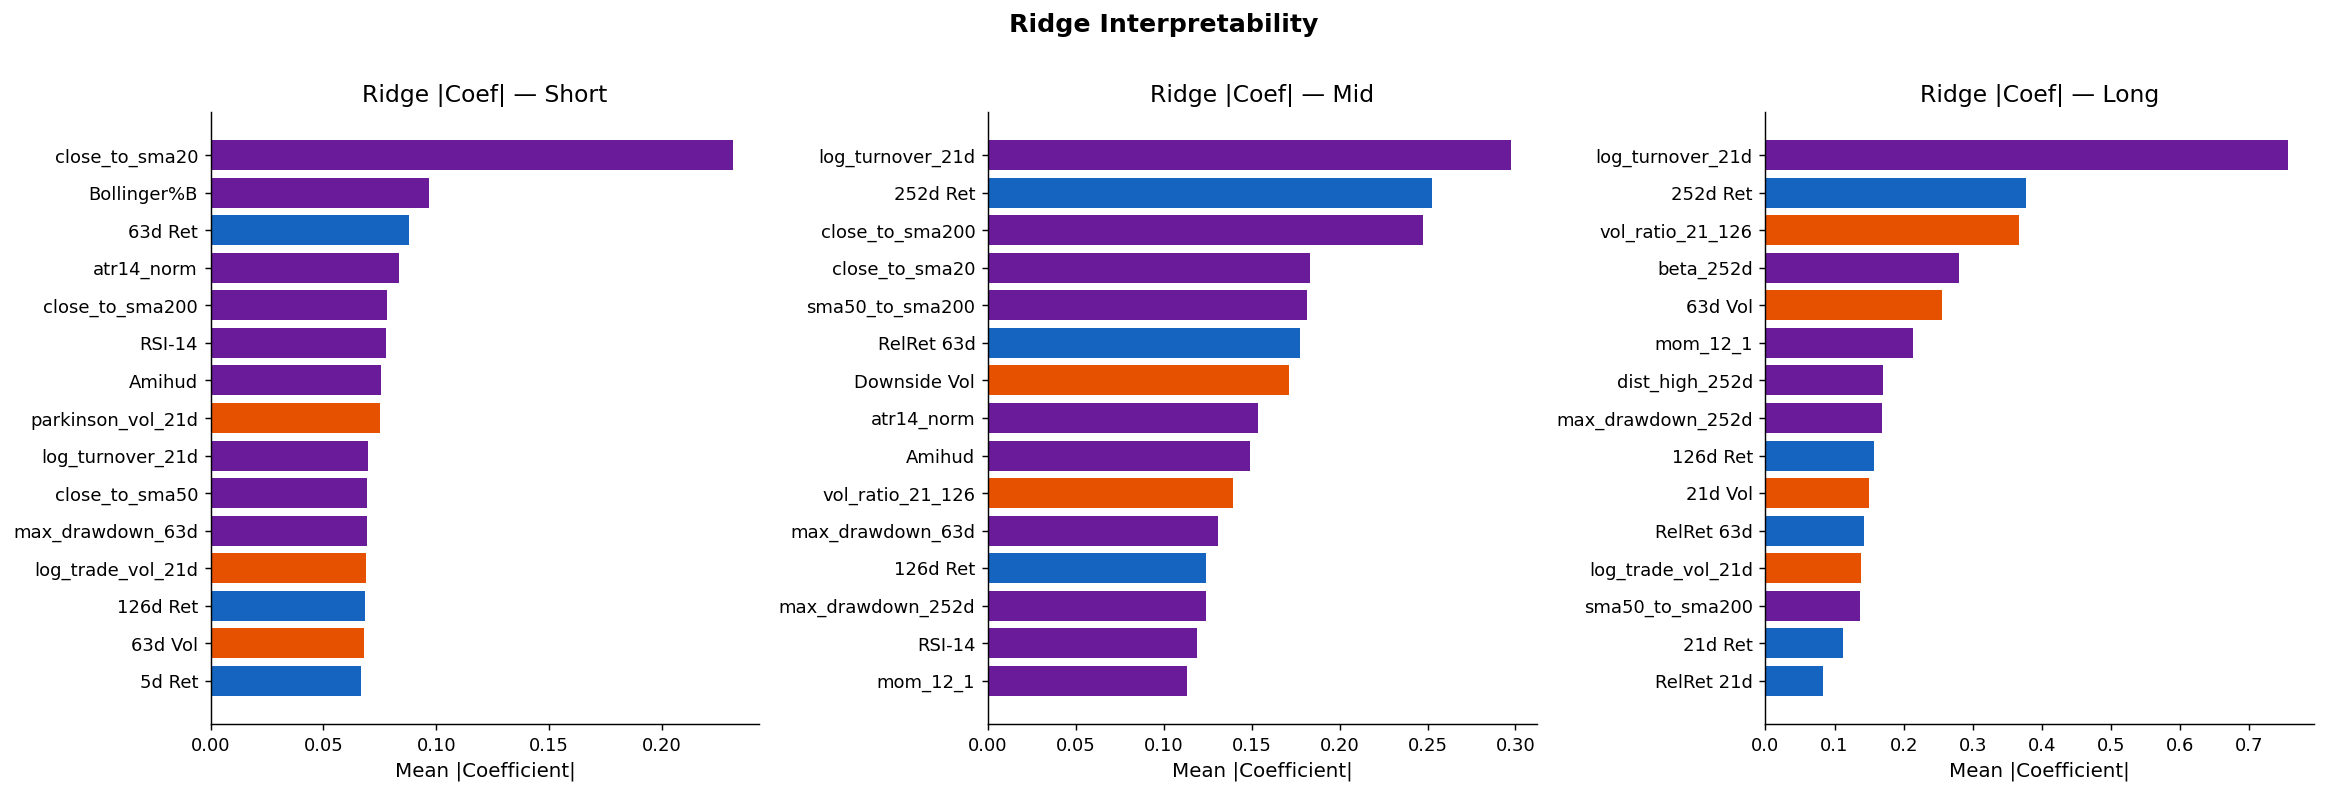

In [31]:
"""10.2 Mean |coefficient| per feature"""
fig, axes = plt.subplots(1,3,figsize=(18,6))
for ax, hz in zip(axes,HORIZONS):
    sub = COEF[(COEF["horizon"]==hz)&(COEF["split_type"]=="dev")]\
        .groupby("feature")["coefficient"].mean().abs()\
        .sort_values(ascending=False).head(15)
    labs = [FEATURE_LABELS.get(f,f) for f in sub.index]
    clrs = ["#1565C0" if "ret" in f else "#E65100" if "vol" in f
            else "#2E7D32" if "rank" in f else "#6A1B9A" for f in sub.index]
    ax.barh(labs[::-1],sub.values[::-1],color=clrs[::-1])
    ax.set_title(f"Ridge |Coef| — {hz.capitalize()}")
    ax.set_xlabel("Mean |Coefficient|")
plt.suptitle("Ridge Interpretability",fontsize=14,fontweight="bold",y=1.01)
plt.tight_layout(); plt.show()

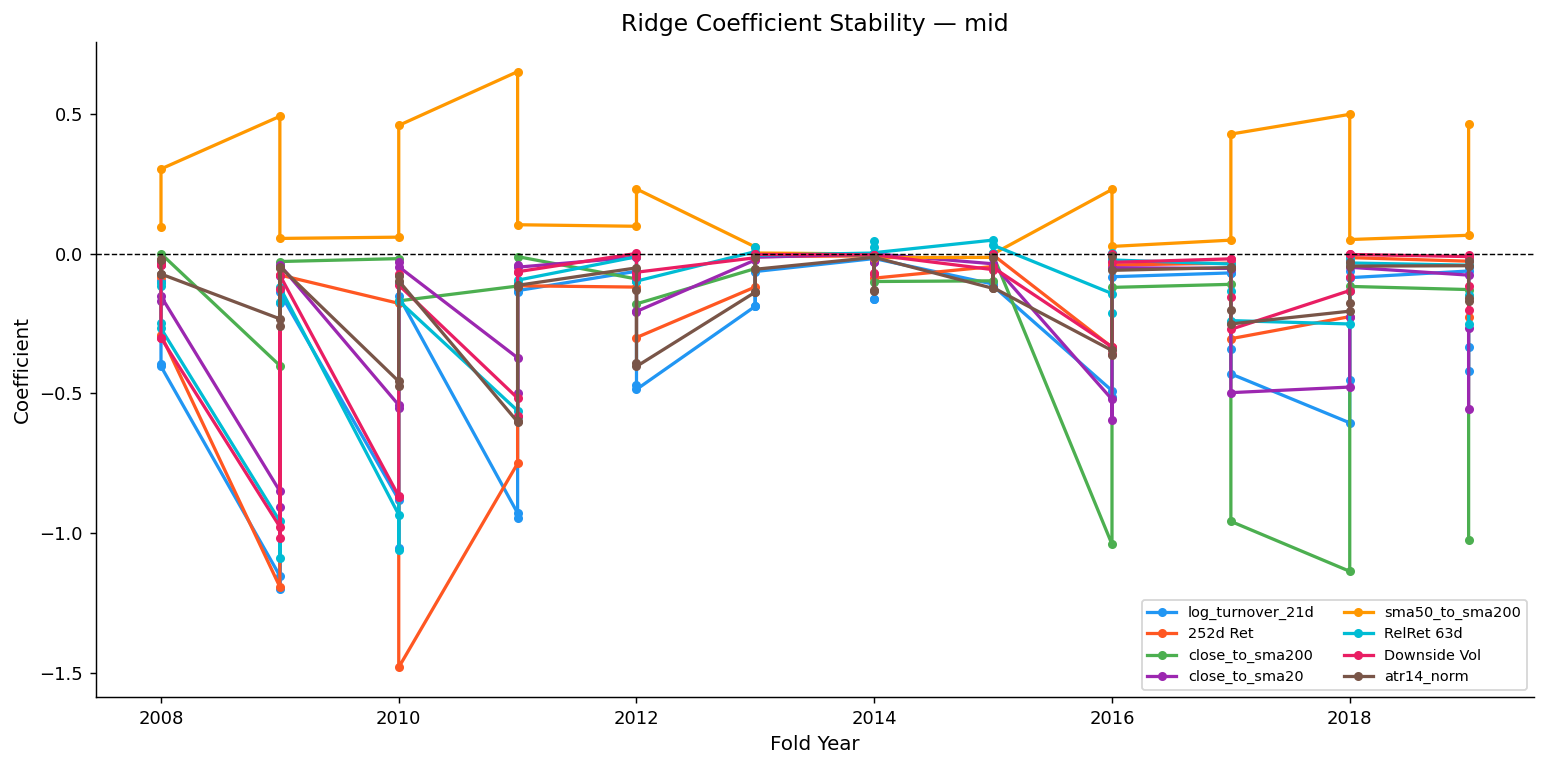

In [32]:
"""10.3 Coefficient stability over folds (mid)"""
hz = "mid"
sub = COEF[(COEF["horizon"]==hz)&(COEF["split_type"]=="dev")]
top_f = sub.groupby("feature")["coefficient"].mean().abs().nlargest(8).index
fig, ax = plt.subplots(figsize=(12,6))
for i,feat in enumerate(top_f):
    fs = sub[sub["feature"]==feat].copy()
    fs = fs[fs["fold"].str.contains(r"\d{4}")].copy()
    if fs.empty: continue
    fs["year"] = fs["fold"].str.extract(r"(\d{4})")[0].astype(int)
    fs = fs.sort_values("year")
    ax.plot(fs["year"],fs["coefficient"],marker="o",ms=4,
            label=FEATURE_LABELS.get(feat,feat),color=PALETTE[i],lw=1.8)
ax.axhline(0,color="black",lw=0.8,ls="--")
ax.set_title(f"Ridge Coefficient Stability — {hz}")
ax.set(xlabel="Fold Year",ylabel="Coefficient")
ax.legend(fontsize=8,ncol=2)
plt.tight_layout(); plt.show()

---
## 11. Explainability — SHAP Values & Permutation Importance

In [33]:
"""11.1 Load SHAP & permutation data"""
SHAP_DF = pd.read_csv(REP / "06_lgbm_shap_values.csv")
PERM_DF = pd.read_csv(REP / "06_lgbm_permutation_importance.csv")
print("SHAP:",SHAP_DF.shape,"| PERM:",PERM_DF.shape)
display(SHAP_DF.head(3))

SHAP: (1020, 6) | PERM: (1020, 6)


,horizon,fold,feature,mean_abs_shap,family,is_identity_proxy
0,short,dev_2008,log_ret_5,0.0,Momentum & Reversal,False
1,short,dev_2008,log_ret_10,0.0,Momentum & Reversal,False
2,short,dev_2008,log_ret_21,0.0,Momentum & Reversal,False


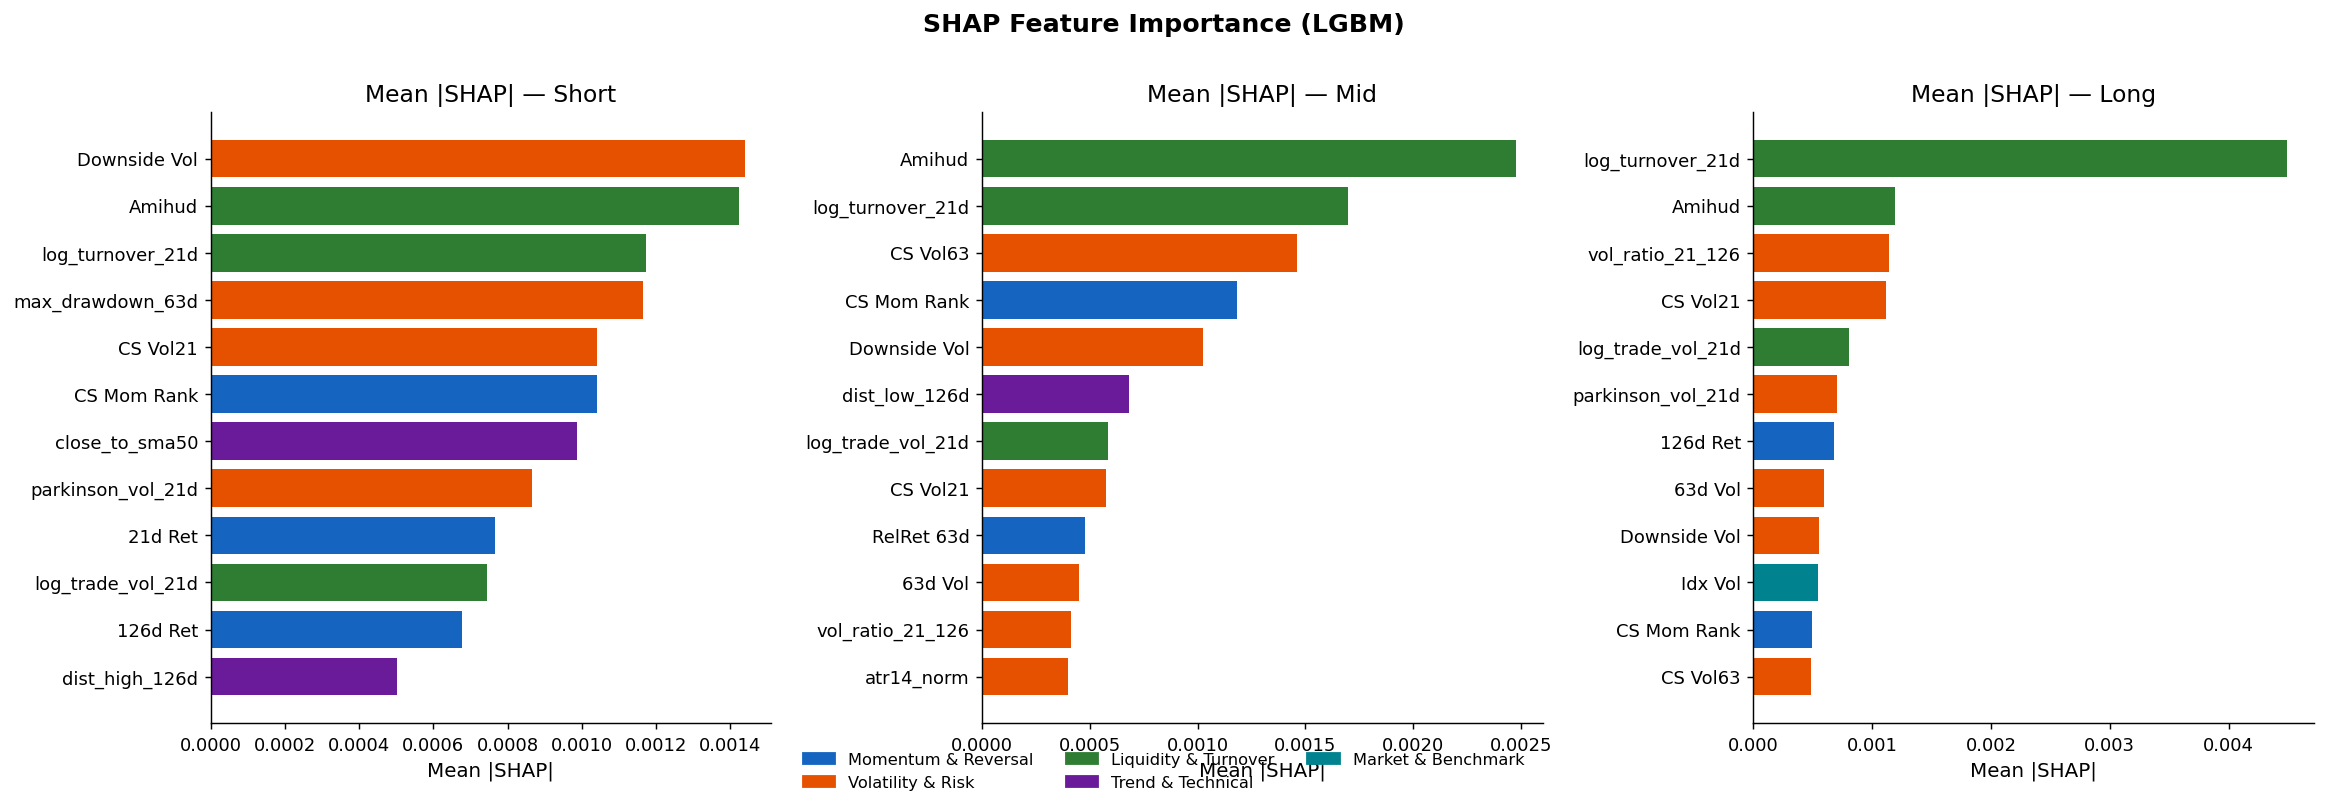

In [34]:
"""11.2 Top SHAP features per horizon"""
FAM_COLORS = {
    "Momentum & Reversal":"#1565C0","Volatility & Risk":"#E65100",
    "Liquidity & Turnover":"#2E7D32","Trend & Technical":"#6A1B9A",
    "Market & Benchmark":"#00838F",
}
fig, axes = plt.subplots(1,3,figsize=(18,6))
for ax, hz in zip(axes,HORIZONS):
    sub = SHAP_DF[SHAP_DF["horizon"]==hz].groupby("feature")["mean_abs_shap"].mean()
    if sub.empty: ax.set_title(f"No SHAP for {hz}"); continue
    top = sub.nlargest(12).sort_values()
    fam_lu = SHAP_DF[SHAP_DF["horizon"]==hz].groupby("feature")["family"].first()
    clrs = [FAM_COLORS.get(fam_lu.get(f,""),"#78909C") for f in top.index]
    ax.barh([FEATURE_LABELS.get(f,f) for f in top.index],top.values,color=clrs)
    ax.set_title(f"Mean |SHAP| — {hz.capitalize()}")
    ax.set_xlabel("Mean |SHAP|")
pats = [mpatches.Patch(color=c,label=k) for k,c in FAM_COLORS.items()]
fig.legend(handles=pats,loc="lower center",ncol=3,fontsize=9,frameon=False)
plt.suptitle("SHAP Feature Importance (LGBM)",fontsize=14,fontweight="bold",y=1.01)
plt.tight_layout(); plt.show()

Spearman ρ (SHAP vs Permutation): 0.309


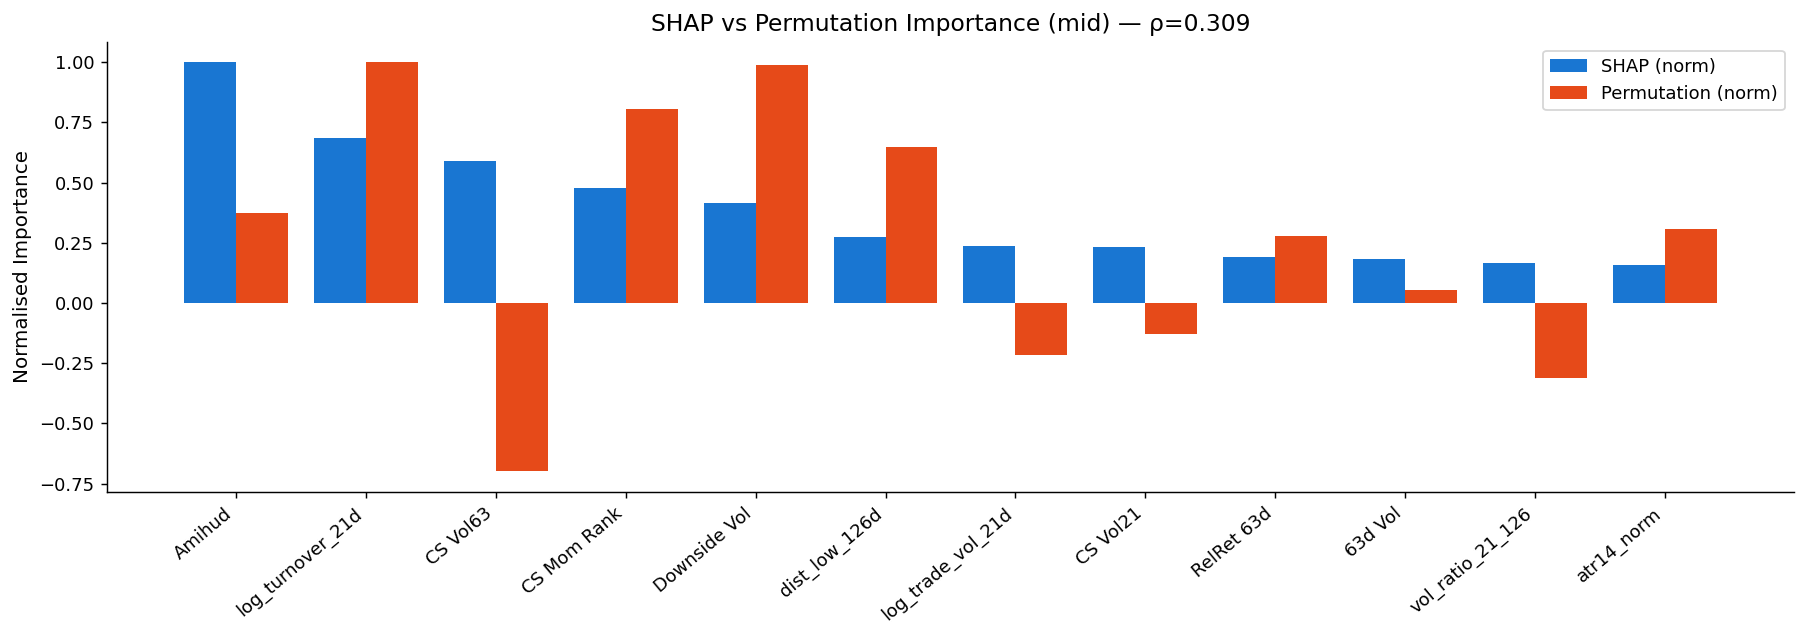

In [35]:
"""11.3 SHAP vs Permutation Importance"""
hz = "mid"
sh = SHAP_DF[SHAP_DF["horizon"]==hz].groupby("feature")["mean_abs_shap"].mean()
pm = PERM_DF[PERM_DF["horizon"]==hz].groupby("feature")["importance"].mean()
comb = pd.DataFrame({"SHAP":sh,"Perm":pm}).dropna()
rho,_ = spearmanr(comb["SHAP"].rank(),comb["Perm"].rank())
print(f"Spearman ρ (SHAP vs Permutation): {rho:.3f}")
comb["SHAP_n"] = comb["SHAP"]/comb["SHAP"].max()
comb["Perm_n"] = comb["Perm"]/comb["Perm"].max()
top = comb.nlargest(12,"SHAP")
x=np.arange(len(top)); w=0.4
fig, ax = plt.subplots(figsize=(14,5))
ax.bar(x-w/2,top["SHAP_n"],w,label="SHAP (norm)",color="#1976D2")
ax.bar(x+w/2,top["Perm_n"],w,label="Permutation (norm)",color="#E64A19")
ax.set_xticks(x)
ax.set_xticklabels([FEATURE_LABELS.get(f,f) for f in top.index],rotation=40,ha="right")
ax.set_title(f"SHAP vs Permutation Importance (mid) — ρ={rho:.3f}")
ax.set_ylabel("Normalised Importance"); ax.legend()
plt.tight_layout(); plt.show()

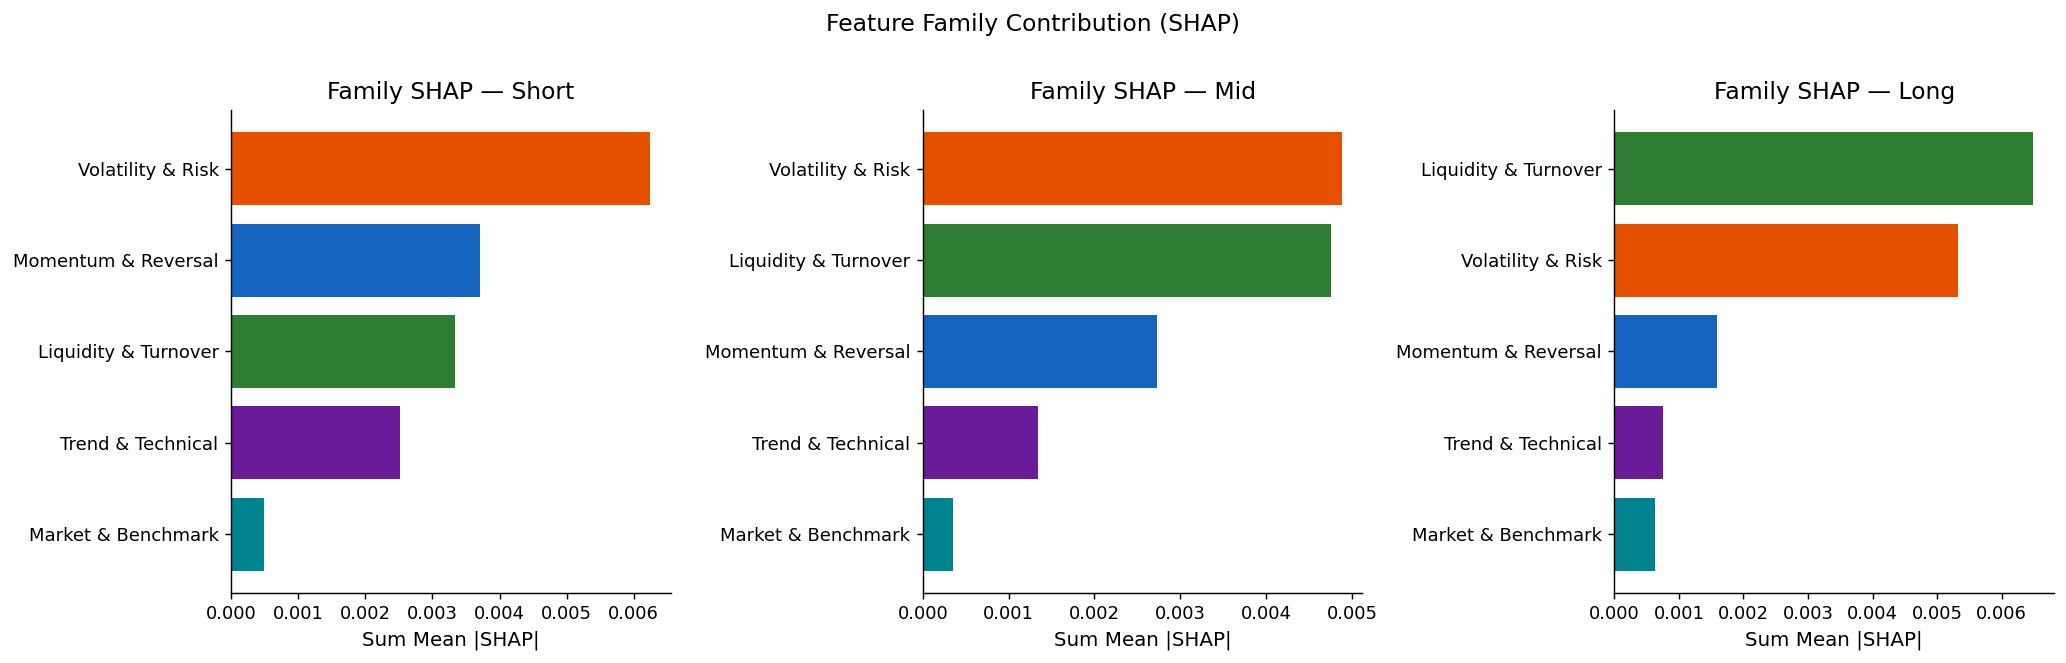

In [36]:
"""11.4 Feature family contribution (SHAP)"""
fig, axes = plt.subplots(1,3,figsize=(16,5))
for ax, hz in zip(axes,HORIZONS):
    sub = SHAP_DF[SHAP_DF["horizon"]==hz]\
        .groupby(["family","feature"])["mean_abs_shap"].mean().reset_index()
    if sub.empty: continue
    fa = sub.groupby("family")["mean_abs_shap"].sum().sort_values()
    clrs = [FAM_COLORS.get(f,"#78909C") for f in fa.index]
    ax.barh(fa.index,fa.values,color=clrs)
    ax.set_title(f"Family SHAP — {hz.capitalize()}")
    ax.set_xlabel("Sum Mean |SHAP|")
plt.suptitle("Feature Family Contribution (SHAP)",fontsize=13,y=1.01)
plt.tight_layout(); plt.show()

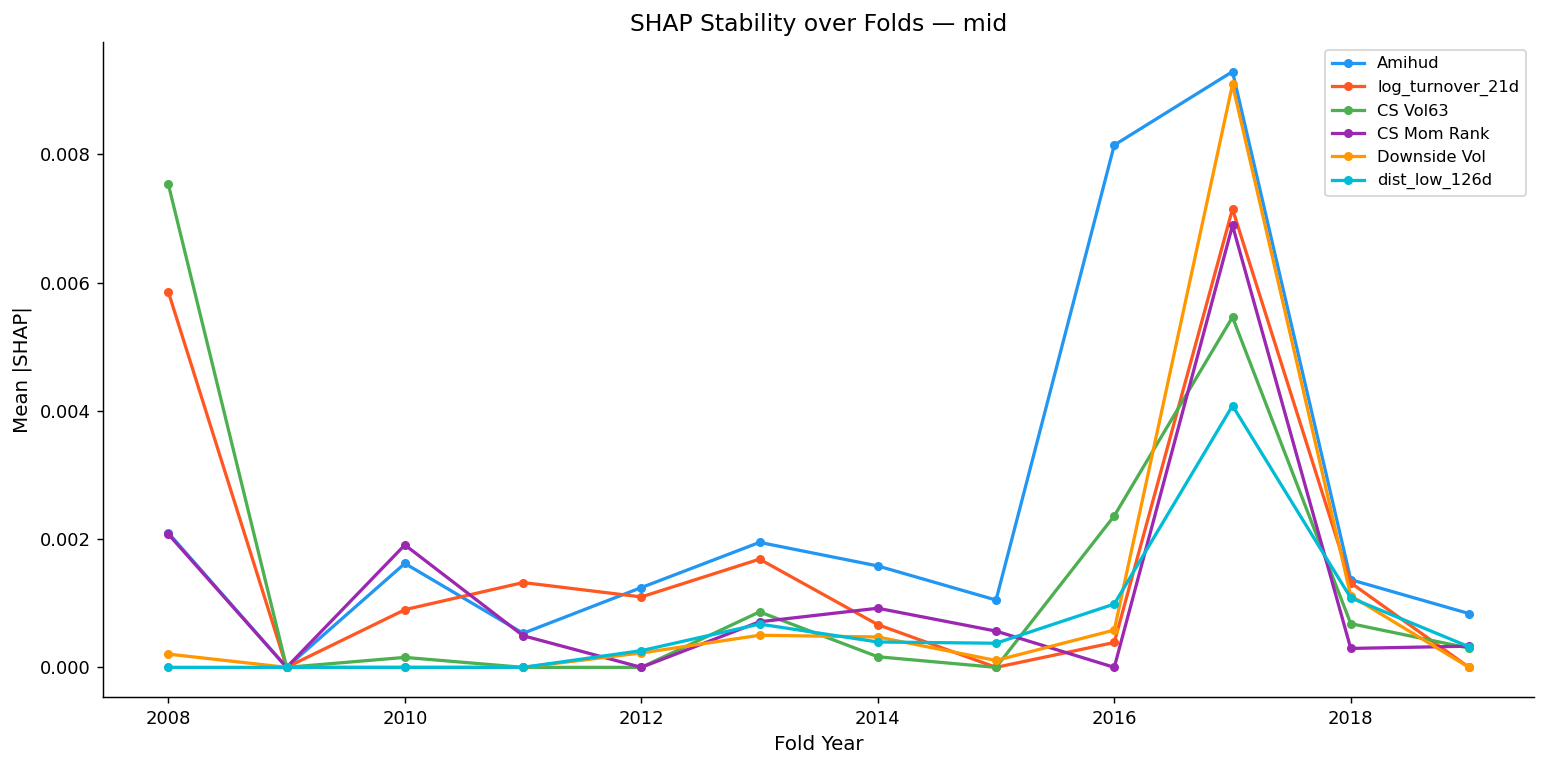

In [37]:
"""11.5 SHAP stability over folds (mid)"""
hz = "mid"
top_f = SHAP_DF[SHAP_DF["horizon"]==hz]\
    .groupby("feature")["mean_abs_shap"].mean().nlargest(6).index
fig, ax = plt.subplots(figsize=(12,6))
for i, feat in enumerate(top_f):
    fs = SHAP_DF[(SHAP_DF["horizon"]==hz)&(SHAP_DF["feature"]==feat)].copy()
    fs = fs[fs["fold"].str.contains(r"\d{4}", na=False)].copy()
    if fs.empty: continue
    fs["year"] = fs["fold"].str.extract(r"(\d{4})")[0].astype(int)
    fs = fs.sort_values("year")
    ax.plot(fs["year"],fs["mean_abs_shap"],marker="o",ms=4,
            label=FEATURE_LABELS.get(feat,feat),color=PALETTE[i],lw=1.8)
ax.set_title(f"SHAP Stability over Folds — {hz}")
ax.set(xlabel="Fold Year",ylabel="Mean |SHAP|"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## 12. Summary Dashboard

In [38]:
"""12.1 Master comparison table"""
sum_rows = []
for m in PRIMARY_MODELS:
    row = {"Model":m}
    for hz in HORIZONS:
        for mt,sh in [("rank_ic_mean","IC"),("top_k_precision","Prec"),
                      ("portfolio_win_rate","WinR")]:
            v = RESULTS[
                (RESULTS["model"]==m)&(RESULTS["horizon"]==hz)&
                (RESULTS["split_type"]=="dev")&(RESULTS["metric"]==mt)
            ]["value"].mean()
            row[f"{hz[0].upper()} {sh}"] = v
    if m in CLF_DF.index:
        row["ROC-AUC"] = CLF_DF.loc[m,"ROC-AUC"]
        row["F1"]      = CLF_DF.loc[m,"F1"]
    rr = REG_DF[(REG_DF["Model"]==m)&(REG_DF["Horizon"]=="mid")]
    if not rr.empty: row["MAE (rank)"] = rr["MAE (rank)"].values[0]
    sum_rows.append(row)
SUMMARY = pd.DataFrame(sum_rows).set_index("Model")
display(show_styled(SUMMARY, caption="Master Summary — S=Short M=Mid L=Long, dev folds"))

=== Master Summary — S=Short M=Mid L=Long, dev folds ===


,S IC,S Prec,S WinR,M IC,M Prec,M WinR,L IC,L Prec,L WinR,ROC-AUC,F1,MAE (rank)
Model,,,,,,,,,,,,
ens_rank4,0.0282,0.5152,0.2564,0.0432,0.5116,0.4373,0.0959,0.5493,0.6727,0.5294,0.5243,0.3173
lgbm_reg,-0.0121,0.4898,0.1838,-0.0007,0.4899,0.3043,0.0442,0.5117,0.3939,0.5176,0.5205,0.3161
rf_reg,0.0029,0.5041,0.1993,0.0109,0.5003,0.3712,0.0359,0.5202,0.5364,0.5155,0.5152,0.3211
ridge,0.0145,0.5116,0.1996,0.0118,0.4995,0.3712,0.0564,0.5210,0.3182,0.5175,0.5136,0.3228
lgbm_clf,0.0037,0.5021,0.2150,0.0002,0.4959,0.3014,0.0612,0.5321,0.4864,0.5090,0.5167,0.3231
rf_clf,0.0019,0.5007,0.2135,-0.0084,0.4825,0.3520,0.0244,0.5160,0.6227,0.4989,0.4851,0.3278
momentum_126,0.0359,0.5236,0.2893,0.0662,0.5173,0.4758,0.0685,0.5541,0.4818,NaN,NaN,0.3174
lstm_reg,0.0454,0.5211,0.2104,0.0218,0.5071,0.2943,-0.0176,0.4932,0.1273,NaN,NaN,0.3332


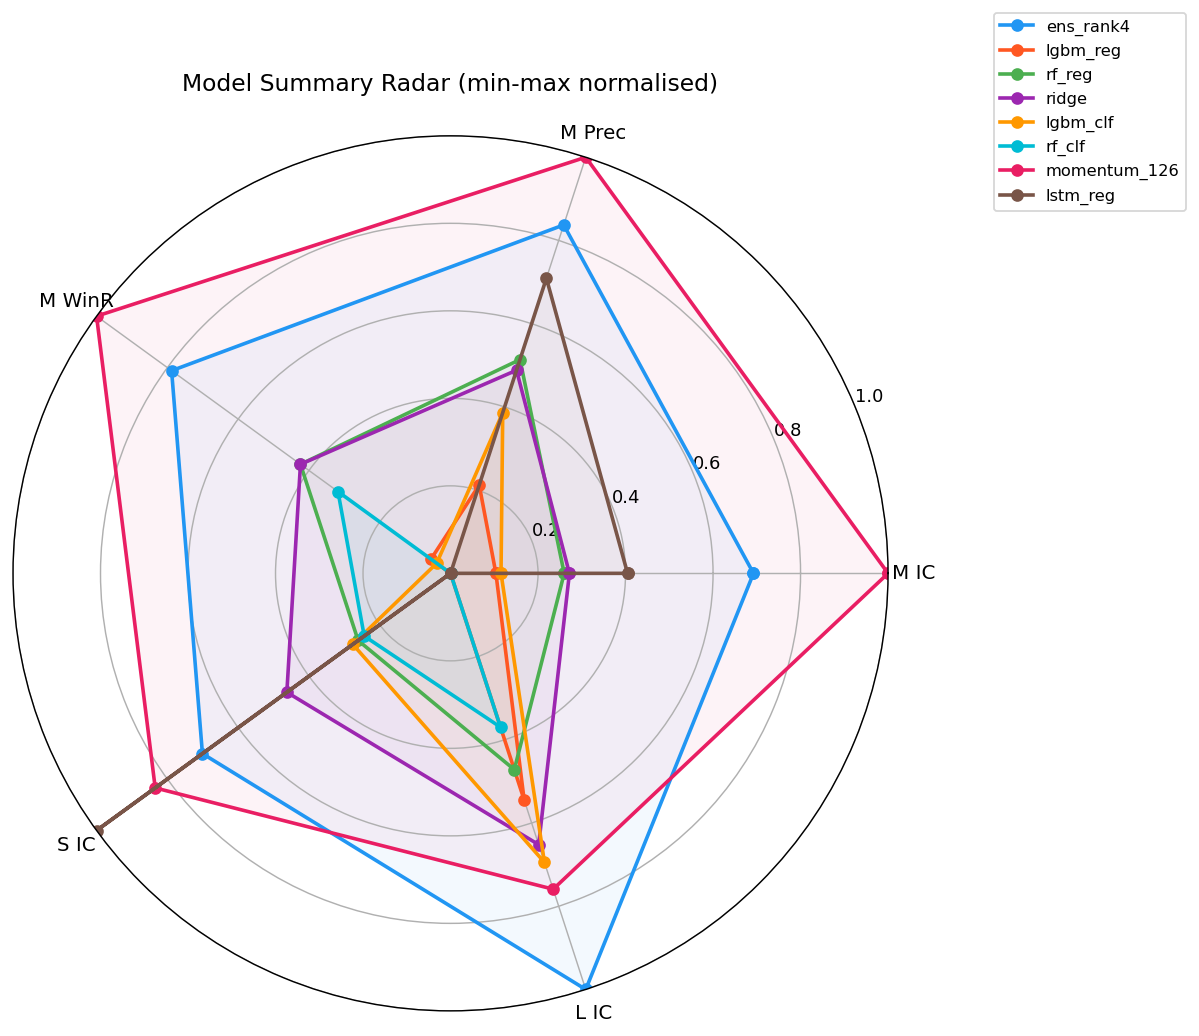

In [39]:
"""12.2 Summary radar"""
DM = ["M IC","M Prec","M WinR","S IC","L IC"]
dash = SUMMARY[[c for c in DM if c in SUMMARY.columns]].dropna(how="all")
def _norm(s):
    r=s.max()-s.min()
    return (s-s.min())/r if r>0 else s*0+0.5
dash_n = dash.apply(_norm)
angles = np.linspace(0,2*np.pi,len(dash_n.columns),endpoint=False).tolist()+[0]
fig, ax = plt.subplots(figsize=(9,8),subplot_kw=dict(polar=True))
for i,(m,row) in enumerate(dash_n.iterrows()):
    v = row.values.tolist()+[row.values[0]]
    ax.plot(angles,v,"o-",lw=2,label=m,color=PALETTE[i%len(PALETTE)])
    ax.fill(angles,v,alpha=0.05,color=PALETTE[i%len(PALETTE)])
ax.set_thetagrids(np.degrees(angles[:-1]),dash_n.columns,fontsize=11)
ax.set_ylim(0,1)
ax.set_title("Model Summary Radar (min-max normalised)",pad=25,fontsize=13)
ax.legend(loc="upper right",bbox_to_anchor=(1.35,1.15),fontsize=9)
plt.tight_layout(); plt.show()

In [40]:
"""12.3 Final text summary"""
print("="*68)
print(" STOCK PULSE — MODEL EVALUATION SUMMARY")
print("="*68)
if "M IC" in SUMMARY.columns:
    best_ic = SUMMARY["M IC"].idxmax()
    print(f"\nBest Rank IC (mid dev) : {best_ic}  ({SUMMARY.loc[best_ic,'M IC']:.4f})")
if "F1" in SUMMARY.columns and SUMMARY["F1"].notna().any():
    bf1 = SUMMARY["F1"].idxmax()
    print(f"Best F1 Score          : {bf1}  ({SUMMARY.loc[bf1,'F1']:.4f})")
if "ROC-AUC" in SUMMARY.columns and SUMMARY["ROC-AUC"].notna().any():
    bauc = SUMMARY["ROC-AUC"].idxmax()
    print(f"Best ROC-AUC           : {bauc}  ({SUMMARY.loc[bauc,'ROC-AUC']:.4f})")
print("\nGeneralisation Gap (Dev IC - Holdout IC, mid):")
mg = GAP_DF[GAP_DF["Horizon"]=="mid"].set_index("Model")
for m in PRIMARY_MODELS:
    if m not in mg.index: continue
    g = mg.loc[m,"Gap"]; flag = "⚠️  OVERFIT?" if g>0.05 else "✓"
    print(f"  {m:20s}  gap={g:+.4f}  {flag}")
ts = SHAP_DF[SHAP_DF["horizon"]=="mid"].groupby("feature")["mean_abs_shap"].mean().idxmax()
print(f"\nTop SHAP Feature (mid) : {FEATURE_LABELS.get(ts,ts)}")
print("\n"+"="*68)

 STOCK PULSE — MODEL EVALUATION SUMMARY

Best Rank IC (mid dev) : momentum_126  (0.0662)
Best F1 Score          : ens_rank4  (0.5243)
Best ROC-AUC           : ens_rank4  (0.5294)

Generalisation Gap (Dev IC - Holdout IC, mid):
  ens_rank4             gap=-0.2743  ✓
  lgbm_reg              gap=-0.1955  ✓
  rf_reg                gap=-0.2057  ✓
  ridge                 gap=-0.4031  ✓
  lgbm_clf              gap=-0.1563  ✓
  rf_clf                gap=-0.3056  ✓
  momentum_126          gap=-0.0474  ✓
  lstm_reg              gap=+0.1123  ⚠️  OVERFIT?

Top SHAP Feature (mid) : Amihud

